In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [20]:

events = pd.read_csv(r"C:\\Users\\cheta\\OneDrive\\Desktop\\PGDA-48\\CP 2\\Datasets\\events.csv")

print("Shape:", events.shape)

Shape: (2756101, 5)


In [21]:
print("Columns:")
print(events.columns.tolist())

print("\nFirst 5 rows:")
display(events.head())

print("\nDataset information:")
events.info()

Columns:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

First 5 rows:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [22]:
missing = pd.DataFrame({
    "Missing Values": events.isnull().sum(),
    "Missing Percentage": (events.isnull().sum() / len(events)) * 100
})

missing = missing.sort_values("Missing Values", ascending=False)

display(missing)

,Missing Values,Missing Percentage
transactionid,2733644,99.18519
timestamp,0,0.00000
visitorid,0,0.00000
event,0,0.00000
itemid,0,0.00000


In [23]:
duplicate_count = events.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(events)) * 100, 4), "%")

Number of duplicate rows: 460
Duplicate percentage: 0.0167 %


In [24]:
print("Event types:")
print(events["event"].value_counts())

print("\nEvent percentages:")
event_percentage = (
    events["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(event_percentage)

Event types:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Event percentages:
event
view           96.67
addtocart       2.52
transaction     0.81
Name: proportion, dtype: float64


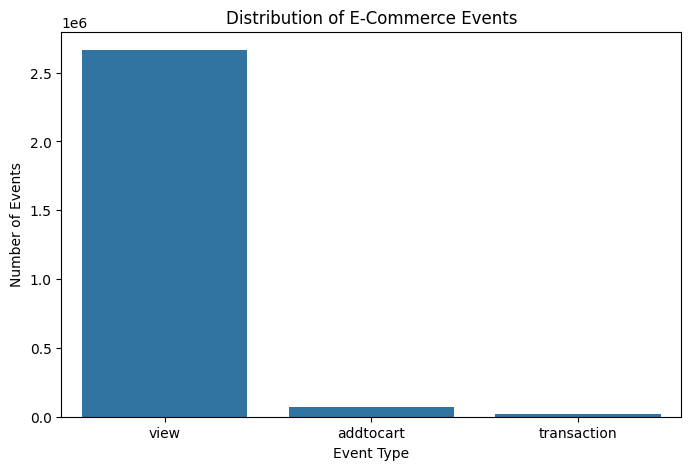

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=events,
    x="event",
    order=events["event"].value_counts().index
)

plt.title("Distribution of E-Commerce Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.show()

In [26]:
print("Unique visitors:", events["visitorid"].nunique())
print("Unique products:", events["itemid"].nunique())
print("Unique transactions:", events["transactionid"].nunique())

Unique visitors: 1407580
Unique products: 235061
Unique transactions: 17672


In [27]:
print("Minimum timestamp:", events["timestamp"].min())
print("Maximum timestamp:", events["timestamp"].max())

print("\nSample timestamps:")
print(events["timestamp"].head(10).tolist())

Minimum timestamp: 1430622004384
Maximum timestamp: 1442545187788

Sample timestamps:
[1433221332117, 1433224214164, 1433221999827, 1433221955914, 1433221337106, 1433224086234, 1433221923240, 1433223291897, 1433220899221, 1433221204592]


In [28]:
id_columns = ["visitorid", "itemid", "transactionid"]

for col in id_columns:
    print(f"\n{col}")
    print("Missing:", events[col].isna().sum())
    print("Unique:", events[col].nunique())


visitorid
Missing: 0
Unique: 1407580

itemid
Missing: 0
Unique: 235061

transactionid
Missing: 2733644
Unique: 17672


In [29]:
display(events.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,2756101.0,NaN,NaN,NaN,1436424488348.103271,3366312180.010336,1430622004384.0,1433478194792.0,1436453013599.0,1439225105168.0,1442545187788.0
visitorid,2756101.0,NaN,NaN,NaN,701922.883229,405687.520809,0.0,350566.0,702060.0,1053437.0,1407579.0
event,2756101,3,view,2664312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
itemid,2756101.0,NaN,NaN,NaN,234922.478375,134195.425214,3.0,118120.0,236067.0,350715.0,466867.0
transactionid,22457.0,NaN,NaN,NaN,8826.497796,5098.99629,0.0,4411.0,8813.0,13224.0,17671.0


In [30]:
# Keep the original dataset untouched
events_raw = events.copy()

# Create working dataframe
events_clean = events.copy()

print("Raw shape:", events_raw.shape)
print("Working shape:", events_clean.shape)

Raw shape: (2756101, 5)
Working shape: (2756101, 5)


In [31]:
duplicate_count = events_clean.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

events_clean = events_clean.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", events_clean.shape)
print("Duplicates remaining:", events_clean.duplicated().sum())

Duplicate rows before removal: 460
Shape after removing duplicates: (2755641, 5)
Duplicates remaining: 0


In [32]:
events_clean["datetime"] = pd.to_datetime(
    events_clean["timestamp"],
    unit="ms"
)

print(events_clean[["timestamp", "datetime"]].head())
print("\nDate range:")
print(events_clean["datetime"].min())
print(events_clean["datetime"].max())

       timestamp                datetime
0  1433221332117 2015-06-02 05:02:12.117
1  1433224214164 2015-06-02 05:50:14.164
2  1433221999827 2015-06-02 05:13:19.827
3  1433221955914 2015-06-02 05:12:35.914
4  1433221337106 2015-06-02 05:02:17.106

Date range:
2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000


In [33]:
print(events_clean["datetime"].isna().sum())
print(events_clean["datetime"].dtype)

0
datetime64[ns]


In [34]:
events_clean["date"] = events_clean["datetime"].dt.date
events_clean["hour"] = events_clean["datetime"].dt.hour
events_clean["day_of_week"] = events_clean["datetime"].dt.dayofweek
events_clean["day_name"] = events_clean["datetime"].dt.day_name()
events_clean["month"] = events_clean["datetime"].dt.month
events_clean["week"] = events_clean["datetime"].dt.isocalendar().week.astype(int)

print(events_clean[
    ["datetime", "date", "hour", "day_of_week", "day_name", "month", "week"]
].head())

                 datetime        date  hour  day_of_week day_name  month  week
0 2015-06-02 05:02:12.117  2015-06-02     5            1  Tuesday      6    23
1 2015-06-02 05:50:14.164  2015-06-02     5            1  Tuesday      6    23
2 2015-06-02 05:13:19.827  2015-06-02     5            1  Tuesday      6    23
3 2015-06-02 05:12:35.914  2015-06-02     5            1  Tuesday      6    23
4 2015-06-02 05:02:17.106  2015-06-02     5            1  Tuesday      6    23


In [35]:
valid_events = {"view", "addtocart", "transaction"}

unexpected_events = set(events_clean["event"].unique()) - valid_events

print("Unexpected event types:", unexpected_events)

Unexpected event types: set()


In [36]:
transaction_events = events_clean[
    events_clean["event"] == "transaction"
]

missing_transaction_ids = transaction_events["transactionid"].isna().sum()

print("Transaction events:", len(transaction_events))
print("Transactions without transaction ID:", missing_transaction_ids)

Transaction events: 22457
Transactions without transaction ID: 0


In [37]:
non_transaction_with_id = events_clean[
    (events_clean["event"] != "transaction") &
    (events_clean["transactionid"].notna())
]

print(
    "Non-transaction events with transaction ID:",
    len(non_transaction_with_id)
)

Non-transaction events with transaction ID: 0


In [38]:
print("visitorid < 0:", (events_clean["visitorid"] < 0).sum())
print("itemid < 0:", (events_clean["itemid"] < 0).sum())
print("timestamp <= 0:", (events_clean["timestamp"] <= 0).sum())

visitorid < 0: 0
itemid < 0: 0
timestamp <= 0: 0


In [39]:
transaction_data = events_clean[
    events_clean["event"] == "transaction"
].copy()

print("Transaction event rows:", len(transaction_data))
print("Unique transaction IDs:", transaction_data["transactionid"].nunique())

print("\nAverage products per transaction:")
print(
    transaction_data.groupby("transactionid")["itemid"]
    .nunique()
    .describe()
)

Transaction event rows: 22457
Unique transaction IDs: 17672

Average products per transaction:
count    17672.000000
mean         1.263185
std          0.940747
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         31.000000
Name: itemid, dtype: float64


In [40]:
events_clean = events_clean.sort_values(
    ["visitorid", "datetime"]
).reset_index(drop=True)

print(events_clean[
    ["visitorid", "datetime", "event", "itemid", "transactionid"]
].head(10))

   visitorid                datetime event  itemid  transactionid
0          0 2015-09-11 20:49:49.439  view  285930            NaN
1          0 2015-09-11 20:52:39.591  view  357564            NaN
2          0 2015-09-11 20:55:17.175  view   67045            NaN
3          1 2015-08-13 17:46:06.444  view   72028            NaN
4          2 2015-08-07 17:51:44.567  view  325215            NaN
5          2 2015-08-07 17:53:33.790  view  325215            NaN
6          2 2015-08-07 17:56:52.664  view  259884            NaN
7          2 2015-08-07 18:01:08.920  view  216305            NaN
8          2 2015-08-07 18:08:25.669  view  342816            NaN
9          2 2015-08-07 18:17:24.375  view  342816            NaN


In [42]:
# Create indicator columns
events_clean["is_view"] = (events_clean["event"] == "view").astype("int8")
events_clean["is_addtocart"] = (events_clean["event"] == "addtocart").astype("int8")
events_clean["is_transaction"] = (events_clean["event"] == "transaction").astype("int8")

# Aggregate visitor activity
visitor_activity = (
    events_clean
    .groupby("visitorid")
    .agg(
        total_events=("event", "size"),
        views=("is_view", "sum"),
        add_to_cart=("is_addtocart", "sum"),
        transactions=("is_transaction", "sum"),
        unique_products=("itemid", "nunique"),
        first_activity=("datetime", "min"),
        last_activity=("datetime", "max")
    )
    .reset_index()
)

print("Visitor activity shape:", visitor_activity.shape)

display(visitor_activity.head())

Visitor activity shape: (1407580, 8)


,visitorid,total_events,views,add_to_cart,transactions,unique_products,first_activity,last_activity
0,0,3,3,0,0,3,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175
1,1,1,1,0,0,1,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444
2,2,8,8,0,0,4,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845
3,3,1,1,0,0,1,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296
4,4,1,1,0,0,1,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167


In [43]:
visitor_activity["purchased"] = (
    visitor_activity["transactions"] > 0
).astype(int)

print(
    visitor_activity["purchased"]
    .value_counts()
)

print("\nPercentages:")
print(
    visitor_activity["purchased"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

purchased
0    1395861
1      11719
Name: count, dtype: int64

Percentages:
purchased
0    99.17
1     0.83
Name: proportion, dtype: float64


In [44]:
print(
    visitor_activity
    .groupby("purchased")[
        [
            "total_events",
            "views",
            "add_to_cart",
            "transactions",
            "unique_products"
        ]
    ]
    .mean()
    .round(2)
)

           total_events  views  add_to_cart  transactions  unique_products
purchased                                                                 
0                  1.81   1.78         0.03          0.00             1.46
1                 19.68  15.42         2.34          1.92             9.54


In [45]:
visitor_activity["activity_duration_hours"] = (
    visitor_activity["last_activity"]
    - visitor_activity["first_activity"]
).dt.total_seconds() / 3600

print(
    visitor_activity["activity_duration_hours"]
    .describe()
    .round(2)
)

count    1407580.00
mean          57.01
std          279.14
min            0.00
25%            0.00
50%            0.00
75%            0.01
max         3311.35
Name: activity_duration_hours, dtype: float64


In [46]:
purchase_times = (
    events_clean[events_clean["event"] == "transaction"]
    .groupby("visitorid")["datetime"]
    .min()
    .reset_index(name="first_purchase")
)

purchase_times = purchase_times.merge(
    visitor_activity[
        ["visitorid", "first_activity"]
    ],
    on="visitorid",
    how="left"
)

purchase_times["hours_to_first_purchase"] = (
    purchase_times["first_purchase"]
    - purchase_times["first_activity"]
).dt.total_seconds() / 3600

print(
    purchase_times["hours_to_first_purchase"]
    .describe()
    .round(2)
)

count    11719.00
mean        91.06
std        326.39
min          0.00
25%          0.10
50%          0.31
75%          4.60
max       3143.52
Name: hours_to_first_purchase, dtype: float64


In [47]:
visitor_activity["activity_duration_hours"] = (
    visitor_activity["last_activity"]
    - visitor_activity["first_activity"]
).dt.total_seconds() / 3600

print(
    visitor_activity["activity_duration_hours"]
    .describe()
    .round(2)
)

count    1407580.00
mean          57.01
std          279.14
min            0.00
25%            0.00
50%            0.00
75%            0.01
max         3311.35
Name: activity_duration_hours, dtype: float64


In [48]:
purchase_times = (
    events_clean[events_clean["event"] == "transaction"]
    .groupby("visitorid")["datetime"]
    .min()
    .reset_index(name="first_purchase")
)

purchase_times = purchase_times.merge(
    visitor_activity[
        ["visitorid", "first_activity"]
    ],
    on="visitorid",
    how="left"
)

purchase_times["hours_to_first_purchase"] = (
    purchase_times["first_purchase"]
    - purchase_times["first_activity"]
).dt.total_seconds() / 3600

print(
    purchase_times["hours_to_first_purchase"]
    .describe()
    .round(2)
)

count    11719.00
mean        91.06
std        326.39
min          0.00
25%          0.10
50%          0.31
75%          4.60
max       3143.52
Name: hours_to_first_purchase, dtype: float64


In [49]:
print("Purchase time percentiles (hours):")

print(
    purchase_times["hours_to_first_purchase"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

Purchase time percentiles (hours):
0.50       0.31
0.75       4.60
0.90     170.92
0.95     595.90
0.99    1893.37
Name: hours_to_first_purchase, dtype: float64


In [50]:
windows = [1, 6, 12, 24, 48, 72]

for hours in windows:
    percentage = (
        purchase_times["hours_to_first_purchase"]
        .le(hours)
        .mean() * 100
    )
    
    print(f"Within {hours:>2} hours: {percentage:.2f}%")

Within  1 hours: 65.95%
Within  6 hours: 75.89%
Within 12 hours: 77.86%
Within 24 hours: 81.65%
Within 48 hours: 84.89%
Within 72 hours: 86.36%


In [51]:
# One prediction point per visitor:
# Use the visitor's last observed activity as the prediction point.

prediction_points = (
    events_clean
    .groupby("visitorid")
    .agg(
        prediction_time=("datetime", "max")
    )
    .reset_index()
)

print("Prediction points:", prediction_points.shape)
prediction_points.head()

Prediction points: (1407580, 2)


,visitorid,prediction_time
0,0,2015-09-11 20:55:17.175
1,1,2015-08-13 17:46:06.444
2,2,2015-08-07 18:20:57.845
3,3,2015-08-01 07:10:35.296
4,4,2015-09-15 21:24:27.167


In [52]:
# Merge each visitor's prediction point back to the event data
events_for_target = events_clean.merge(
    prediction_points,
    on="visitorid",
    how="left"
)

# Events occurring AFTER the prediction point
future_events = events_for_target[
    events_for_target["datetime"] > events_for_target["prediction_time"]
]

# Check future transactions
future_purchases = (
    future_events[future_events["event"] == "transaction"]
    .groupby("visitorid")
    .size()
    .rename("future_transactions")
)

prediction_points = prediction_points.merge(
    future_purchases,
    on="visitorid",
    how="left"
)

prediction_points["future_transactions"] = (
    prediction_points["future_transactions"]
    .fillna(0)
)

prediction_points["purchase_next_24h"] = (
    prediction_points["future_transactions"] > 0
).astype(int)

print(
    prediction_points["purchase_next_24h"]
    .value_counts()
)

purchase_next_24h
0    1407580
Name: count, dtype: int64


In [53]:
events_session = events_clean[
    ["visitorid", "datetime", "event", "itemid", "transactionid"]
].copy()

events_session = events_session.sort_values(
    ["visitorid", "datetime"]
).reset_index(drop=True)

events_session["previous_datetime"] = (
    events_session
    .groupby("visitorid")["datetime"]
    .shift(1)
)

events_session["gap_minutes"] = (
    events_session["datetime"]
    - events_session["previous_datetime"]
).dt.total_seconds() / 60

print(
    events_session["gap_minutes"]
    .describe()
    .round(2)
)

count    1348061.00
mean        3571.74
std        15068.45
min            0.00
25%            0.64
50%            2.28
75%           40.92
max       196457.52
Name: gap_minutes, dtype: float64


In [54]:
gap_values = events_session["gap_minutes"].dropna()

print("Gap percentiles (minutes):")

print(
    gap_values
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

Gap percentiles (minutes):
0.50        2.28
0.75       40.92
0.90     4394.83
0.95    19848.28
0.99    86016.42
Name: gap_minutes, dtype: float64


In [55]:
thresholds = [15, 30, 60, 120]

for threshold in thresholds:
    percentage = (
        gap_values > threshold
    ).mean() * 100
    
    print(
        f"Gaps greater than {threshold:>3} minutes: "
        f"{percentage:.2f}%"
    )

Gaps greater than  15 minutes: 29.79%
Gaps greater than  30 minutes: 26.27%
Gaps greater than  60 minutes: 23.67%
Gaps greater than 120 minutes: 21.61%


In [56]:
events_session["new_session"] = (
    events_session["gap_minutes"] > 30
).astype(int)

events_session["session_number"] = (
    events_session
    .groupby("visitorid")["new_session"]
    .cumsum()
)

events_session["session_id"] = (
    events_session["visitorid"].astype(str)
    + "_"
    + events_session["session_number"].astype(str)
)

print(
    events_session[
        [
            "visitorid",
            "datetime",
            "event",
            "gap_minutes",
            "session_number",
            "session_id"
        ]
    ].head(20)
)

    visitorid                datetime      event  gap_minutes  session_number  \
0           0 2015-09-11 20:49:49.439       view          NaN               0   
1           0 2015-09-11 20:52:39.591       view     2.835867               0   
2           0 2015-09-11 20:55:17.175       view     2.626400               0   
3           1 2015-08-13 17:46:06.444       view          NaN               0   
4           2 2015-08-07 17:51:44.567       view          NaN               0   
5           2 2015-08-07 17:53:33.790       view     1.820383               0   
6           2 2015-08-07 17:56:52.664       view     3.314567               0   
7           2 2015-08-07 18:01:08.920       view     4.270933               0   
8           2 2015-08-07 18:08:25.669       view     7.279150               0   
9           2 2015-08-07 18:17:24.375       view     8.978433               0   
10          2 2015-08-07 18:17:43.170       view     0.313250               0   
11          2 2015-08-07 18:

In [57]:
# Create numeric indicators first
events_session["is_view"] = (
    events_session["event"] == "view"
).astype("int8")

events_session["is_addtocart"] = (
    events_session["event"] == "addtocart"
).astype("int8")

events_session["is_transaction"] = (
    events_session["event"] == "transaction"
).astype("int8")

# Fast session aggregation
session_summary = (
    events_session
    .groupby(["visitorid", "session_id"], sort=False)
    .agg(
        session_start=("datetime", "min"),
        session_end=("datetime", "max"),
        total_events=("event", "size"),
        views=("is_view", "sum"),
        add_to_cart=("is_addtocart", "sum"),
        transactions=("is_transaction", "sum"),
        unique_products=("itemid", "nunique")
    )
    .reset_index()
)

# Session duration
session_summary["session_duration_minutes"] = (
    session_summary["session_end"]
    - session_summary["session_start"]
).dt.total_seconds() / 60

print("Total sessions:", len(session_summary))
print("Unique visitors:", session_summary["visitorid"].nunique())

session_summary.head()

Total sessions: 1761675
Unique visitors: 1407580


,visitorid,session_id,session_start,session_end,total_events,views,add_to_cart,transactions,unique_products,session_duration_minutes
0,0,0_0,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175,3,3,0,0,3,5.462267
1,1,1_0,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444,1,1,0,0,1,0.000000
2,2,2_0,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845,8,8,0,0,4,29.221300
3,3,3_0,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296,1,1,0,0,1,0.000000
4,4,4_0,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167,1,1,0,0,1,0.000000


In [58]:
print(
    session_summary[
        [
            "total_events",
            "views",
            "add_to_cart",
            "transactions",
            "unique_products",
            "session_duration_minutes"
        ]
    ].describe()
    .round(2)
)

       total_events       views  add_to_cart  transactions  unique_products  \
count    1761675.00  1761675.00   1761675.00    1761675.00       1761675.00   
mean           1.56        1.51         0.04          0.01             1.33   
std            2.60        2.35         0.40          0.21             1.78   
min            1.00        0.00         0.00          0.00             1.00   
25%            1.00        1.00         0.00          0.00             1.00   
50%            1.00        1.00         0.00          0.00             1.00   
75%            1.00        1.00         0.00          0.00             1.00   
max          417.00      417.00       114.00         59.00           389.00   

       session_duration_minutes  
count                1761675.00  
mean                       1.75  
std                        8.33  
min                        0.00  
25%                        0.00  
50%                        0.00  
75%                        0.00  
max             

In [59]:
session_summary["has_purchase"] = (
    session_summary["transactions"] > 0
).astype("int8")

print(
    session_summary["has_purchase"].value_counts()
)

print("\nPercentage:")
print(
    session_summary["has_purchase"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

has_purchase
0    1747378
1      14297
Name: count, dtype: int64

Percentage:
has_purchase
0    99.19
1     0.81
Name: proportion, dtype: float64


In [60]:
session_counts = (
    session_summary
    .groupby("visitorid")
    .agg(
        total_sessions=("session_id", "nunique"),
        first_session=("session_start", "min"),
        last_session=("session_end", "max")
    )
    .reset_index()
)

print(session_counts["total_sessions"].describe())

print("\nVisitors by number of sessions:")
print(
    session_counts["total_sessions"]
    .value_counts()
    .sort_index()
    .head(20)
)

count    1.407580e+06
mean     1.251563e+00
std      1.818195e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.620000e+02
Name: total_sessions, dtype: float64

Visitors by number of sessions:
total_sessions
1     1225947
2      123003
3       31061
4       11688
5        5534
6        3084
7        1808
8        1210
9         836
10        569
11        450
12        346
13        246
14        210
15        175
16        146
17        124
18        105
19         99
20         78
Name: count, dtype: int64


In [61]:
multi_session_visitors = (
    session_counts["total_sessions"] > 1
).sum()

single_session_visitors = (
    session_counts["total_sessions"] == 1
).sum()

print("Single-session visitors:", single_session_visitors)
print("Multi-session visitors:", multi_session_visitors)

print(
    "\nPercentage with multiple sessions:",
    round(
        multi_session_visitors /
        len(session_counts) * 100,
        2
    ),
    "%"
)

Single-session visitors: 1225947
Multi-session visitors: 181633

Percentage with multiple sessions: 12.9 %


In [62]:
print(
    session_counts["total_sessions"]
    .quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

0.50    1.0
0.75    1.0
0.90    2.0
0.95    2.0
0.99    5.0
Name: total_sessions, dtype: float64


In [63]:
# Create a clean session-level modeling base

model_sessions = session_summary.copy()

# Make sure sessions are ordered chronologically
model_sessions = model_sessions.sort_values(
    ["visitorid", "session_start"]
).reset_index(drop=True)

# Historical session count BEFORE the current session
model_sessions["previous_session_count"] = (
    model_sessions.groupby("visitorid").cumcount()
)

# Historical purchases BEFORE the current session
model_sessions["previous_purchase_count"] = (
    model_sessions.groupby("visitorid")["has_purchase"]
    .cumsum()
    - model_sessions["has_purchase"]
)

# Previous session end time
model_sessions["previous_session_end"] = (
    model_sessions.groupby("visitorid")["session_end"].shift(1)
)

# Time since previous session (hours)
model_sessions["hours_since_previous_session"] = (
    (
        model_sessions["session_start"]
        - model_sessions["previous_session_end"]
    ).dt.total_seconds() / 3600
)

# Fill first-session values
model_sessions["hours_since_previous_session"] = (
    model_sessions["hours_since_previous_session"]
    .fillna(-1)
)

print("Modeling base shape:", model_sessions.shape)

print("\nColumns:")
print(model_sessions.columns.tolist())

print("\nSample:")
print(
    model_sessions[
        [
            "visitorid",
            "session_id",
            "session_start",
            "session_end",
            "total_events",
            "views",
            "add_to_cart",
            "unique_products",
            "session_duration_minutes",
            "previous_session_count",
            "previous_purchase_count",
            "hours_since_previous_session",
            "has_purchase"
        ]
    ].head(10)
)

Modeling base shape: (1761675, 15)

Columns:
['visitorid', 'session_id', 'session_start', 'session_end', 'total_events', 'views', 'add_to_cart', 'transactions', 'unique_products', 'session_duration_minutes', 'has_purchase', 'previous_session_count', 'previous_purchase_count', 'previous_session_end', 'hours_since_previous_session']

Sample:
   visitorid session_id           session_start             session_end  \
0          0        0_0 2015-09-11 20:49:49.439 2015-09-11 20:55:17.175   
1          1        1_0 2015-08-13 17:46:06.444 2015-08-13 17:46:06.444   
2          2        2_0 2015-08-07 17:51:44.567 2015-08-07 18:20:57.845   
3          3        3_0 2015-08-01 07:10:35.296 2015-08-01 07:10:35.296   
4          4        4_0 2015-09-15 21:24:27.167 2015-09-15 21:24:27.167   
5          5        5_0 2015-07-17 01:45:56.439 2015-07-17 01:45:56.439   
6          6        6_0 2015-08-30 06:03:48.202 2015-08-30 06:03:48.202   
7          6        6_1 2015-08-30 06:39:38.318 2015-08-30

In [64]:
# ============================================================
# Create future purchase target
# Target:
# 1 = visitor makes a purchase within 24 hours after
#     the current session ends
# 0 = no purchase within the next 24 hours
# ============================================================

# Dataset maximum timestamp
dataset_end = events_clean["datetime"].max()

# Sessions that already contain a purchase cannot be prediction points
prediction_sessions = model_sessions[
    model_sessions["has_purchase"] == 0
].copy()

# Exclude sessions too close to the end of the dataset.
# Otherwise, we cannot observe the complete 24-hour future window.
prediction_sessions = prediction_sessions[
    prediction_sessions["session_end"] <= dataset_end - pd.Timedelta(hours=24)
].copy()

print("Eligible prediction sessions:", len(prediction_sessions))
print("Dataset end:", dataset_end)

Eligible prediction sessions: 1740684
Dataset end: 2015-09-18 02:59:47.788000


In [65]:
# ============================================================
# Create future purchase target - corrected version
# ============================================================

# Start with sessions that did NOT contain a purchase
prediction_sessions = model_sessions[
    model_sessions["has_purchase"] == 0
].copy()

# Exclude sessions within the final 24 hours of the dataset
# because their complete future window is not observable.
dataset_end = events_clean["datetime"].max()

prediction_sessions = prediction_sessions[
    prediction_sessions["session_end"] <=
    dataset_end - pd.Timedelta(hours=24)
].copy()

print("Eligible prediction sessions:", len(prediction_sessions))
print("Dataset end:", dataset_end)


# ------------------------------------------------------------
# Transaction timestamps
# ------------------------------------------------------------

transaction_times = (
    events_clean.loc[
        events_clean["event"] == "transaction",
        ["visitorid", "datetime"]
    ]
    .rename(columns={"datetime": "transaction_time"})
    .copy()
)

# ------------------------------------------------------------
# IMPORTANT:
# merge_asof requires the actual merge keys to be globally
# sorted by the time column.
# ------------------------------------------------------------

prediction_sessions = prediction_sessions.sort_values(
    ["session_end", "visitorid"]
).reset_index(drop=True)

transaction_times = transaction_times.sort_values(
    ["transaction_time", "visitorid"]
).reset_index(drop=True)


# ------------------------------------------------------------
# Find the first transaction after each session
# ------------------------------------------------------------

prediction_sessions = pd.merge_asof(
    prediction_sessions,
    transaction_times,
    left_on="session_end",
    right_on="transaction_time",
    by="visitorid",
    direction="forward",
    allow_exact_matches=False
)


# ------------------------------------------------------------
# Calculate time until next purchase
# ------------------------------------------------------------

prediction_sessions["hours_to_next_purchase"] = (
    prediction_sessions["transaction_time"]
    - prediction_sessions["session_end"]
).dt.total_seconds() / 3600


# ------------------------------------------------------------
# Create final target
# ------------------------------------------------------------

prediction_sessions["purchase_next_24h"] = (
    prediction_sessions["hours_to_next_purchase"].notna()
    &
    (prediction_sessions["hours_to_next_purchase"] <= 24)
).astype(int)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nTarget distribution:")
print(
    prediction_sessions["purchase_next_24h"]
    .value_counts()
)

print("\nTarget percentage:")
print(
    prediction_sessions["purchase_next_24h"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Eligible prediction sessions: 1740684
Dataset end: 2015-09-18 02:59:47.788000

Target distribution:
purchase_next_24h
0    1734669
1       6015
Name: count, dtype: int64

Target percentage:
purchase_next_24h
0    99.65
1     0.35
Name: proportion, dtype: float64


In [66]:
# ============================================================
# Create time-based behavioral features
# ============================================================

prediction_sessions["session_hour"] = (
    prediction_sessions["session_start"].dt.hour
)

prediction_sessions["day_of_week"] = (
    prediction_sessions["session_start"].dt.dayofweek
)

prediction_sessions["is_weekend"] = (
    prediction_sessions["day_of_week"] >= 5
).astype(int)

# Optional: month within the dataset
prediction_sessions["month"] = (
    prediction_sessions["session_start"].dt.month
)

print(
    prediction_sessions[
        [
            "session_hour",
            "day_of_week",
            "is_weekend",
            "month"
        ]
    ].head()
)

   session_hour  day_of_week  is_weekend  month
0             3            6           1      5
1             3            6           1      5
2             3            6           1      5
3             3            6           1      5
4             3            6           1      5


In [67]:
# ============================================================
# Select final features for purchase-intent prediction
# ============================================================

feature_columns = [
    "total_events",
    "views",
    "add_to_cart",
    "unique_products",
    "session_duration_minutes",
    "session_hour",
    "day_of_week",
    "is_weekend",
    "month",
    "previous_session_count",
    "previous_purchase_count",
    "hours_since_previous_session"
]

target_column = "purchase_next_24h"

model_data = prediction_sessions[
    feature_columns + [target_column]
].copy()

print("Final modeling dataset shape:", model_data.shape)

print("\nFeatures:")
for i, col in enumerate(feature_columns, 1):
    print(f"{i}. {col}")

print("\nTarget:")
print(target_column)

Final modeling dataset shape: (1740684, 13)

Features:
1. total_events
2. views
3. add_to_cart
4. unique_products
5. session_duration_minutes
6. session_hour
7. day_of_week
8. is_weekend
9. month
10. previous_session_count
11. previous_purchase_count
12. hours_since_previous_session

Target:
purchase_next_24h


In [68]:
# ============================================================
# Feature quality check
# ============================================================

print("Missing values:")
print(model_data.isnull().sum())

print("\nInfinite values:")
print(
    np.isinf(
        model_data.select_dtypes(include=np.number)
    ).sum()
)

print("\nData types:")
print(model_data.dtypes)

print("\nDuplicate modeling rows:")
print(model_data.duplicated().sum())

print("\nTarget distribution:")
print(model_data[target_column].value_counts())

Missing values:
total_events                    0
views                           0
add_to_cart                     0
unique_products                 0
session_duration_minutes        0
session_hour                    0
day_of_week                     0
is_weekend                      0
month                           0
previous_session_count          0
previous_purchase_count         0
hours_since_previous_session    0
purchase_next_24h               0
dtype: int64

Infinite values:
total_events                    0
views                           0
add_to_cart                     0
unique_products                 0
session_duration_minutes        0
session_hour                    0
day_of_week                     0
is_weekend                      0
month                           0
previous_session_count          0
previous_purchase_count         0
hours_since_previous_session    0
purchase_next_24h               0
dtype: int64

Data types:
total_events                      int64
vie

In [69]:
# ============================================================
# Numerical feature statistics
# ============================================================

print(
    model_data[feature_columns].describe().T
)

                                  count       mean         std  min  25%  \
total_events                  1740684.0   1.500666    1.981315  1.0  1.0   
views                         1740684.0   1.473674    1.903459  0.0  1.0   
add_to_cart                   1740684.0   0.026992    0.311915  0.0  0.0   
unique_products               1740684.0   1.305038    1.446791  1.0  1.0   
session_duration_minutes      1740684.0   1.532346    6.240015  0.0  0.0   
session_hour                  1740684.0  12.684539    7.853564  0.0  4.0   
day_of_week                   1740684.0   2.780790    1.971868  0.0  1.0   
is_weekend                    1740684.0   0.237033    0.425263  0.0  0.0   
month                         1740684.0   6.797245    1.291781  5.0  6.0   
previous_session_count        1740684.0   1.381909   11.051038  0.0  0.0   
previous_purchase_count       1740684.0   0.045618    1.206437  0.0  0.0   
hours_since_previous_session  1740684.0  44.533940  220.382847 -1.0 -1.0   

           

In [70]:
# ============================================================
# Chronological train / validation / test split
# ============================================================

# Keep the session timestamp alongside the modeling data
model_data = prediction_sessions[
    feature_columns + [target_column, "session_end"]
].copy()

# Sort chronologically
model_data = model_data.sort_values(
    "session_end"
).reset_index(drop=True)

# Calculate split points
n = len(model_data)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

# Split chronologically
train_data = model_data.iloc[:train_end].copy()

validation_data = model_data.iloc[
    train_end:validation_end
].copy()

test_data = model_data.iloc[
    validation_end:
].copy()

print("Train shape:", train_data.shape)
print("Validation shape:", validation_data.shape)
print("Test shape:", test_data.shape)

print("\nDate ranges:")

print(
    "Train:",
    train_data["session_end"].min(),
    "→",
    train_data["session_end"].max()
)

print(
    "Validation:",
    validation_data["session_end"].min(),
    "→",
    validation_data["session_end"].max()
)

print(
    "Test:",
    test_data["session_end"].min(),
    "→",
    test_data["session_end"].max()
)

Train shape: (1218478, 14)
Validation shape: (261103, 14)
Test shape: (261103, 14)

Date ranges:
Train: 2015-05-03 03:00:11.289000 → 2015-08-04 02:52:14.880000
Validation: 2015-08-04 02:52:23.006000 → 2015-08-26 04:44:34.239000
Test: 2015-08-26 04:44:48.233000 → 2015-09-17 02:59:37.058000


In [71]:
# ============================================================
# Target distribution across chronological splits
# ============================================================

for name, data in [
    ("Train", train_data),
    ("Validation", validation_data),
    ("Test", test_data)
]:
    
    print(f"\n{name}")
    print("-" * 40)
    
    print(
        data[target_column]
        .value_counts()
    )
    
    print(
        data[target_column]
        .value_counts(normalize=True)
        .mul(100)
        .round(3)
    )


Train
----------------------------------------
purchase_next_24h
0    1214367
1       4111
Name: count, dtype: int64
purchase_next_24h
0    99.663
1     0.337
Name: proportion, dtype: float64

Validation
----------------------------------------
purchase_next_24h
0    260150
1       953
Name: count, dtype: int64
purchase_next_24h
0    99.635
1     0.365
Name: proportion, dtype: float64

Test
----------------------------------------
purchase_next_24h
0    260152
1       951
Name: count, dtype: int64
purchase_next_24h
0    99.636
1     0.364
Name: proportion, dtype: float64


In [72]:
# ============================================================
# Positive-class counts
# ============================================================

print(
    "Training positives:",
    train_data[target_column].sum()
)

print(
    "Validation positives:",
    validation_data[target_column].sum()
)

print(
    "Test positives:",
    test_data[target_column].sum()
)

Training positives: 4111
Validation positives: 953
Test positives: 951


In [73]:
# ============================================================
# Prepare X and y
# ============================================================

X_train = train_data[feature_columns].copy()
y_train = train_data[target_column].copy()

X_val = validation_data[feature_columns].copy()
y_val = validation_data[target_column].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[target_column].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

X_train: (1218478, 12)
y_train: (1218478,)
X_val: (261103, 12)
y_val: (261103,)
X_test: (261103, 12)
y_test: (261103,)

Training target:
purchase_next_24h
0    1214367
1       4111
Name: count, dtype: int64


In [74]:
# ============================================================
# Feature scaling
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

print("\nTraining feature means after scaling:")
print(X_train_scaled.mean(axis=0).round(4))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0).round(4))

Scaled training shape: (1218478, 12)
Scaled validation shape: (261103, 12)
Scaled test shape: (261103, 12)

Training feature means after scaling:
[ 0. -0.  0. -0.  0.  0. -0.  0.  0. -0.  0. -0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [75]:
# ============================================================
# Calculate class weights
# ============================================================

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, class_weights_array)
)

print("Classes:", classes)
print("Class weights:", class_weights)

Classes: [0 1]
Class weights: {np.int64(0): np.float64(0.5016926513978064), np.int64(1): np.float64(148.1972756020433)}


In [76]:
# ============================================================
# BASELINE MODEL 1 — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import time

print("Training Logistic Regression...")

start_time = time.time()

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

training_time = time.time() - start_time

print(
    f"Training completed in {training_time:.2f} seconds"
)

Training Logistic Regression...
Training completed in 1.94 seconds


In [77]:
# ============================================================
# Logistic Regression — Validation Evaluation
# ============================================================

y_val_proba_lr = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

# Default threshold
y_val_pred_lr = (
    y_val_proba_lr >= 0.5
).astype(int)

print("ROC-AUC:",
      round(roc_auc_score(y_val, y_val_proba_lr), 4))

print("PR-AUC:",
      round(average_precision_score(y_val, y_val_proba_lr), 4))

print("Precision:",
      round(precision_score(y_val, y_val_pred_lr, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, y_val_pred_lr, zero_division=0), 4))

print("F1:",
      round(f1_score(y_val, y_val_pred_lr, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))

ROC-AUC: 0.8636
PR-AUC: 0.1602
Precision: 0.0382
Recall: 0.6464
F1: 0.0721

Confusion Matrix:
[[244625  15525]
 [   337    616]]


In [78]:
# ============================================================
# BASELINE MODEL 2 — RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier
import time

print("Training Random Forest...")

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

rf_training_time = time.time() - start_time

print(
    f"Training completed in {rf_training_time:.2f} seconds"
)

Training Random Forest...
Training completed in 40.56 seconds


In [79]:
# ============================================================
# Random Forest — Validation Evaluation
# ============================================================

y_val_proba_rf = rf_model.predict_proba(
    X_val
)[:, 1]

y_val_pred_rf = (
    y_val_proba_rf >= 0.5
).astype(int)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, y_val_proba_rf), 4)
)

print(
    "PR-AUC:",
    round(
        average_precision_score(y_val, y_val_proba_rf),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_val,
            y_val_pred_rf,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_val,
            y_val_pred_rf,
            zero_division=0
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_val,
            y_val_pred_rf,
            zero_division=0
        ),
        4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_rf
    )
)

ROC-AUC: 0.8652
PR-AUC: 0.1953
Precision: 0.0695
Recall: 0.4995
F1: 0.122

Confusion Matrix:
[[253776   6374]
 [   477    476]]


In [80]:
# ============================================================
# ANN Model — Baseline
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.random.set_seed(42)

# Build ANN
ann_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(1, activation="sigmoid")
])

# Compile
ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

# Display architecture
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
# ============================================================
# ANN — Training
# ============================================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=20,
    batch_size=4096,

    class_weight={
        0: float(class_weights[0]),
        1: float(class_weights[1])
    },

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.5192 - pr_auc: 0.0653 - roc_auc: 0.8116 - val_loss: 0.4176 - val_pr_auc: 0.1005 - val_roc_auc: 0.8684
Epoch 2/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.4812 - pr_auc: 0.0781 - roc_auc: 0.8404 - val_loss: 0.3983 - val_pr_auc: 0.1106 - val_roc_auc: 0.8740
Epoch 3/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.4715 - pr_auc: 0.0841 - roc_auc: 0.8494 - val_loss: 0.3792 - val_pr_auc: 0.1239 - val_roc_auc: 0.8805
Epoch 4/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.4650 - pr_auc: 0.0907 - roc_auc: 0.8525 - val_loss: 0.3849 - val_pr_auc: 0.1293 - val_roc_auc: 0.8828
Epoch 5/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.4598 - pr_auc: 0.0933 - roc_auc: 0.8571 - val_loss: 0.3699 - val_pr_auc: 0.1366 - val_roc_auc: 0.8851
Epoch 6/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.4529 - pr_auc: 0.0978 - roc_auc: 0.8626 - val_loss: 0.3683 - val_pr_auc: 0.1409 - val_roc_auc: 0.8879
Epoch 7/20
298/

In [82]:
# ============================================================
# ANN — Validation Evaluation
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Prediction probabilities
y_val_proba_ann = ann_model.predict(
    X_val_scaled,
    batch_size=4096
).ravel()

# Class predictions using default threshold
y_val_pred_ann = (
    y_val_proba_ann >= 0.5
).astype(int)

# ROC-AUC
print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_val, y_val_proba_ann),
        4
    )
)

# PR-AUC
print(
    "PR-AUC:",
    round(
        average_precision_score(y_val, y_val_proba_ann),
        4
    )
)

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_ann,
        target_names=[
            "No Purchase",
            "Purchase"
        ],
        zero_division=0
    )
)

# Confusion Matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_ann
    )
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ROC-AUC: 0.8951
PR-AUC: 0.1932

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      0.91      0.95    260150
    Purchase       0.03      0.73      0.05       953

    accuracy                           0.91    261103
   macro avg       0.51      0.82      0.50    261103
weighted avg       1.00      0.91      0.95    261103


Confusion Matrix:
[[236128  24022]
 [   259    694]]


In [83]:
# ============================================================
# ANN Hyperparameter Tuning — Setup
# ============================================================

ann_class_weights = {
    0: float(class_weights[0]),
    1: float(class_weights[1])
}

print("Class weights:", ann_class_weights)
print("Training samples:", X_train_scaled.shape[0])
print("Validation samples:", X_val_scaled.shape[0])

Class weights: {0: 0.5016926513978064, 1: 148.1972756020433}
Training samples: 1218478
Validation samples: 261103


In [84]:
# ============================================================
# ANN Tuning — Configuration 1
# Larger Network
# ============================================================

ann_tuned_1 = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(1, activation="sigmoid")
])

ann_tuned_1.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

ann_tuned_1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,985 (39.00 KB)

 Trainable params: 9,985 (39.00 KB)

 Non-trainable params: 0 (0.00 B)

In [85]:
# ============================================================
# Configuration 1 — Training
# ============================================================

early_stopping_tuned = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_tuned_1 = ann_tuned_1.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=20,
    batch_size=4096,

    class_weight=ann_class_weights,

    callbacks=[early_stopping_tuned],

    verbose=1
)

Epoch 1/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.5011 - pr_auc: 0.0743 - roc_auc: 0.8249 - val_loss: 0.4201 - val_pr_auc: 0.1106 - val_roc_auc: 0.8712
Epoch 2/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.4723 - pr_auc: 0.0863 - roc_auc: 0.8493 - val_loss: 0.3970 - val_pr_auc: 0.1251 - val_roc_auc: 0.8782
Epoch 3/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.4628 - pr_auc: 0.0911 - roc_auc: 0.8550 - val_loss: 0.3973 - val_pr_auc: 0.1355 - val_roc_auc: 0.8839
Epoch 4/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4560 - pr_auc: 0.0999 - roc_auc: 0.8597 - val_loss: 0.3926 - val_pr_auc: 0.1387 - val_roc_auc: 0.8865
Epoch 5/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.4502 - pr_auc: 0.1027 - roc_auc: 0.8639 - val_loss: 0.3613 - val_pr_auc: 0.1435 - val_roc_auc: 0.8895
Epoch 6/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4471 - pr_auc: 0.1023 - roc_auc: 0.8666 - val_loss: 0.3825 - val_pr_auc: 0.1428 - val_roc_auc: 0.8896
Epoch 7/20

In [86]:
# ============================================================
# Configuration 1 — Validation Evaluation
# ============================================================

y_val_proba_tuned_1 = ann_tuned_1.predict(
    X_val_scaled,
    batch_size=4096
).ravel()

y_val_pred_tuned_1 = (
    y_val_proba_tuned_1 >= 0.5
).astype(int)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_val, y_val_proba_tuned_1),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_val,
            y_val_proba_tuned_1
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_tuned_1,
        target_names=[
            "No Purchase",
            "Purchase"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_tuned_1
    )
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
ROC-AUC: 0.8954
PR-AUC: 0.2145

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      0.91      0.95    260150
    Purchase       0.03      0.73      0.05       953

    accuracy                           0.91    261103
   macro avg       0.51      0.82      0.50    261103
weighted avg       1.00      0.91      0.95    261103


Confusion Matrix:
[[235818  24332]
 [   257    696]]


In [87]:
# ============================================================
# ANN Tuning — Configuration 2
# Lower Learning Rate + Lighter Dropout
# ============================================================

ann_tuned_2 = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.10),

    layers.Dense(1, activation="sigmoid")
])

ann_tuned_2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

ann_tuned_2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,985 (39.00 KB)

 Trainable params: 9,985 (39.00 KB)

 Non-trainable params: 0 (0.00 B)

In [88]:
# ============================================================
# Configuration 2 — Training
# ============================================================

early_stopping_tuned_2 = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_tuned_2 = ann_tuned_2.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=20,
    batch_size=4096,

    class_weight=ann_class_weights,

    callbacks=[early_stopping_tuned_2],

    verbose=1
)

Epoch 1/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.4981 - pr_auc: 0.0739 - roc_auc: 0.8303 - val_loss: 0.3826 - val_pr_auc: 0.1039 - val_roc_auc: 0.8705
Epoch 2/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4708 - pr_auc: 0.0845 - roc_auc: 0.8500 - val_loss: 0.3793 - val_pr_auc: 0.1207 - val_roc_auc: 0.8779
Epoch 3/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4648 - pr_auc: 0.0933 - roc_auc: 0.8528 - val_loss: 0.4105 - val_pr_auc: 0.1244 - val_roc_auc: 0.8807
Epoch 4/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4569 - pr_auc: 0.0982 - roc_auc: 0.8592 - val_loss: 0.4019 - val_pr_auc: 0.1346 - val_roc_auc: 0.8843
Epoch 5/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4534 - pr_auc: 0.1005 - roc_auc: 0.8619 - val_loss: 0.4077 - val_pr_auc: 0.1337 - val_roc_auc: 0.8861
Epoch 6/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4515 - pr_auc: 0.1050 - roc_auc: 0.8626 - val_loss: 0.3957 - val_pr_auc: 0.1410 - val_roc_auc: 0.8880
Epoch 7/20

In [89]:
# ============================================================
# Configuration 2 — Validation Evaluation
# ============================================================

y_val_proba_tuned_2 = ann_tuned_2.predict(
    X_val_scaled,
    batch_size=4096
).ravel()

y_val_pred_tuned_2 = (
    y_val_proba_tuned_2 >= 0.5
).astype(int)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(y_val, y_val_proba_tuned_2),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_val,
            y_val_proba_tuned_2
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_tuned_2,
        target_names=[
            "No Purchase",
            "Purchase"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_tuned_2
    )
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
ROC-AUC: 0.8931
PR-AUC: 0.1908

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      0.88      0.94    260150
    Purchase       0.02      0.76      0.04       953

    accuracy                           0.88    261103
   macro avg       0.51      0.82      0.49    261103
weighted avg       1.00      0.88      0.93    261103


Confusion Matrix:
[[229495  30655]
 [   227    726]]


In [91]:
print("ANN model:", "ann_model" in globals())
print("X_val_scaled:", "X_val_scaled" in globals())
print("y_val:", "y_val" in globals())

ANN model: True
X_val_scaled: True
y_val: True


In [92]:
y_val_proba_best_ann = ann_model.predict(
    X_val_scaled,
    batch_size=4096,
    verbose=1
).ravel()

print("Validation probabilities shape:", y_val_proba_best_ann.shape)
print("Minimum probability:", y_val_proba_best_ann.min())
print("Maximum probability:", y_val_proba_best_ann.max())

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Validation probabilities shape: (261103,)
Minimum probability: 0.02940678
Maximum probability: 1.0


In [93]:
# ============================================================
# Threshold Optimization — 0.05 to 0.95
# ============================================================

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        y_val_proba_best_ann >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

# Display all thresholds
print(
    threshold_df.round(4).to_string(index=False)
)

# Best threshold based on F1
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("\nBest Threshold:")
print(best_threshold_row)

 Threshold  Precision  Recall     F1
      0.05     0.0037  0.9990 0.0073
      0.06     0.0037  0.9990 0.0073
      0.07     0.0037  0.9990 0.0073
      0.08     0.0037  0.9979 0.0073
      0.09     0.0037  0.9969 0.0073
      0.10     0.0037  0.9969 0.0074
      0.11     0.0037  0.9958 0.0074
      0.12     0.0038  0.9906 0.0076
      0.13     0.0040  0.9874 0.0079
      0.14     0.0043  0.9780 0.0085
      0.15     0.0049  0.9675 0.0098
      0.16     0.0053  0.9549 0.0106
      0.17     0.0057  0.9517 0.0113
      0.18     0.0060  0.9444 0.0120
      0.19     0.0064  0.9370 0.0127
      0.20     0.0072  0.9307 0.0144
      0.21     0.0083  0.9150 0.0164
      0.22     0.0111  0.8856 0.0219
      0.23     0.0114  0.8846 0.0224
      0.24     0.0117  0.8835 0.0231
      0.25     0.0120  0.8783 0.0237
      0.26     0.0124  0.8730 0.0244
      0.27     0.0127  0.8657 0.0251
      0.28     0.0131  0.8604 0.0258
      0.29     0.0135  0.8583 0.0267
      0.30     0.0140  0.8562 0.0276
 

In [94]:
# ============================================================
# Best Threshold — Validation Confusion Matrix
# ============================================================

best_threshold = 0.94

y_val_pred_best = (
    y_val_proba_best_ann >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_best,
        target_names=[
            "No Purchase",
            "Purchase"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_best
    )
)

Selected Threshold: 0.94

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      1.00      1.00    260150
    Purchase       0.22      0.31      0.26       953

    accuracy                           0.99    261103
   macro avg       0.61      0.65      0.63    261103
weighted avg       0.99      0.99      0.99    261103


Confusion Matrix:
[[259115   1035]
 [   654    299]]


In [95]:
# ============================================================
# FINAL TEST EVALUATION — ANN Tuned 1
# ============================================================

best_threshold = 0.94
from sklearn.metrics import accuracy_score


# Predict probabilities on untouched test set
y_test_proba = ann_tuned_1.predict(
    X_test_scaled,
    batch_size=4096,
    verbose=1
).ravel()

# ROC-AUC and PR-AUC
test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

test_pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

# Apply selected validation threshold
y_test_pred = (
    y_test_proba >= best_threshold
).astype(int)

# Classification metrics
test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

print("=" * 60)
print("FINAL TEST RESULTS — ANN TUNED 1")
print("=" * 60)

print(f"Threshold : {best_threshold}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")
print(f"PR-AUC    : {test_pr_auc:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"Accuracy  : {test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "No Purchase",
            "Purchase"
        ],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred
    )
)

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
FINAL TEST RESULTS — ANN TUNED 1
Threshold : 0.94
ROC-AUC   : 0.8825
PR-AUC    : 0.2245
Precision : 0.2532
Recall    : 0.4006
F1 Score  : 0.3103
Accuracy  : 0.9935

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      1.00      1.00    260152
    Purchase       0.25      0.40      0.31       951

    accuracy                           0.99    261103
   macro avg       0.63      0.70      0.65    261103
weighted avg       1.00      0.99      0.99    261103

Confusion Matrix:
[[259028   1124]
 [   570    381]]


In [96]:
import pandas as pd

# Load both RetailRocket item properties files
item_properties_1 = pd.read_csv("C:\\Users\\cheta\\OneDrive\\Desktop\\PGDA-48\\CP 2\\Datasets\\item_properties_part1.csv")
item_properties_2 = pd.read_csv("C:\\Users\\cheta\\OneDrive\\Desktop\\PGDA-48\\CP 2\\Datasets\\item_properties_part2.csv")

print("=" * 60)
print("PART 1")
print("=" * 60)
print("Shape:", item_properties_1.shape)
print("Columns:", item_properties_1.columns.tolist())
print("\nData Types:")
print(item_properties_1.dtypes)
print("\nMissing Values:")
print(item_properties_1.isna().sum())
print("\nDuplicate Rows:", item_properties_1.duplicated().sum())

print("\nFirst 5 rows:")
display(item_properties_1.head())


print("\n" + "=" * 60)
print("PART 2")
print("=" * 60)
print("Shape:", item_properties_2.shape)
print("Columns:", item_properties_2.columns.tolist())
print("\nData Types:")
print(item_properties_2.dtypes)
print("\nMissing Values:")
print(item_properties_2.isna().sum())
print("\nDuplicate Rows:", item_properties_2.duplicated().sum())

print("\nFirst 5 rows:")
display(item_properties_2.head())


print("\n" + "=" * 60)
print("STRUCTURE CHECK")
print("=" * 60)

print("Same columns:",
      item_properties_1.columns.tolist() ==
      item_properties_2.columns.tolist())

print("Same data types:",
      item_properties_1.dtypes.equals(
          item_properties_2.dtypes
      ))

PART 1
Shape: (10999999, 4)
Columns: ['timestamp', 'itemid', 'property', 'value']

Data Types:
timestamp     int64
itemid        int64
property     object
value        object
dtype: object

Missing Values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Duplicate Rows: 0

First 5 rows:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513



PART 2
Shape: (9275903, 4)
Columns: ['timestamp', 'itemid', 'property', 'value']

Data Types:
timestamp     int64
itemid        int64
property     object
value        object
dtype: object

Missing Values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Duplicate Rows: 0

First 5 rows:


,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062



STRUCTURE CHECK
Same columns: True
Same data types: True


In [98]:
# Combine Part 1 and Part 2
item_properties = pd.concat(
    [
        item_properties_1,
        item_properties_2
    ],
    ignore_index=True
)

print("Combined Shape:", item_properties.shape)

print("\nColumns:")
print(item_properties.columns.tolist())

print("\nMissing Values:")
print(item_properties.isna().sum())

print("\nDuplicate Rows:")
print(item_properties.duplicated().sum())

Combined Shape: (20275902, 4)

Columns:
['timestamp', 'itemid', 'property', 'value']

Missing Values:
timestamp    0
itemid       0
property     0
value        0
dtype: int64

Duplicate Rows:
0


In [99]:
# Check the most common product properties

property_counts = (
    item_properties["property"]
    .value_counts()
    .reset_index()
)

property_counts.columns = ["property", "count"]

print("Number of unique properties:", item_properties["property"].nunique())
print("\nTop 30 properties:")
display(property_counts.head(30))

Number of unique properties: 1104

Top 30 properties:


,property,count
0,888,3000398
1,790,1790516
2,available,1503639
3,categoryid,788214
4,6,631471
5,283,597419
6,776,574220
7,678,481966
8,364,476486
9,202,448938


In [100]:
# Inspect the values associated with the most common properties

top_properties = property_counts.head(15)["property"].tolist()

for prop in top_properties:
    subset = item_properties[item_properties["property"] == prop]

    print(f"\n{'='*60}")
    print(f"Property: {prop}")
    print(f"Rows: {len(subset):,}")
    print(f"Unique values: {subset['value'].nunique():,}")
    print("Sample values:")
    print(subset["value"].drop_duplicates().head(10).tolist())


Property: 888
Rows: 3,000,398
Unique values: 454,723
Sample values:
['1116713 960601 n277.200', '1038400 45956 n504.000', '1292080', '150169 176547 824301 24474 293011 1240134', '599031', '883447 726612', '1051803 1227205 n712862568.000 992862 951748 690896 n30.000 1135780 1284577 n187.200 1284577 n16392.000 628176 n9216.000 134030 1284577 n72.000 1187104 1284577 n12.000 1175087 n12.000 1072114 1284577 1186729 681805 1284577 618514 980588 927741 32766 1284577 1141052 n48.000 288796 1284577 842796 1154859', '1024724 220869', 'n120.000 586893 1166722 237874 43137', '297660 1301543']

Property: 790
Rows: 1,790,516
Unique values: 33,052
Sample values:
['n15360.000', 'n21000.000', 'n5400.000', 'n39588.000', 'n10320.000', 'n185280.000', 'n11160.000', 'n15588.000', 'n191736.000', 'n54048.000']

Property: available
Rows: 1,503,639
Unique values: 2
Sample values:
['0', '1']

Property: categoryid
Rows: 788,214
Unique values: 1,242
Sample values:
['1338', '1277', '1059', '1147', '47', '619', '12

In [101]:
# Product coverage for each property

property_coverage = (
    item_properties.groupby("property")["itemid"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

property_coverage.columns = ["property", "unique_products"]

print("Total unique products:", item_properties["itemid"].nunique())
print("\nTop 30 properties by product coverage:")

display(property_coverage.head(30))

Total unique products: 417053

Top 30 properties by product coverage:


,property,unique_products
0,available,417053
1,categoryid,417053
2,283,417053
3,364,417053
4,790,417053
5,112,417053
6,764,417053
7,888,417053
8,159,417053
9,678,417019


In [102]:
# Analyze the information content of the high-coverage properties

candidate_properties = property_coverage.head(30)["property"].tolist()

property_analysis = []

for prop in candidate_properties:
    subset = item_properties[item_properties["property"] == prop]

    property_analysis.append({
        "property": prop,
        "products": subset["itemid"].nunique(),
        "unique_values": subset["value"].nunique(),
        "values_per_product": round(
            subset.groupby("itemid")["value"].nunique().mean(), 2
        )
    })

property_analysis = pd.DataFrame(property_analysis)

display(
    property_analysis.sort_values(
        ["products", "unique_values"],
        ascending=[False, False]
    )
)

,property,products,unique_values,values_per_product
7,888,417053,454723,1.38
3,364,417053,420554,1.01
2,283,417053,333165,1.03
4,790,417053,33052,1.82
1,categoryid,417053,1242,1.06
0,available,417053,2,1.16
5,112,417053,1,1.00
6,764,417053,1,1.00
8,159,417053,1,1.00
9,678,417019,3832,1.01


In [103]:
# Load category tree dataset

category_tree = pd.read_csv("C:\\Users\\cheta\\OneDrive\\Desktop\\PGDA-48\\CP 2\\Datasets\\category_tree.csv")

print("Category tree shape:", category_tree.shape)

print("\nColumns:")
print(category_tree.columns.tolist())

print("\nMissing values:")
print(category_tree.isna().sum())

print("\nSample:")
display(category_tree.head(20))

Category tree shape: (1669, 2)

Columns:
['categoryid', 'parentid']

Missing values:
categoryid     0
parentid      25
dtype: int64

Sample:


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
5,231,NaN
6,542,378.0
7,1146,542.0
8,1140,542.0
9,1479,1537.0


In [104]:
# Check category mapping coverage

product_categories = item_properties[
    item_properties["property"] == "categoryid"
][["itemid", "value"]].copy()

product_categories = product_categories.rename(
    columns={"value": "categoryid"}
)

# Convert category IDs to numeric for matching
product_categories["categoryid"] = pd.to_numeric(
    product_categories["categoryid"],
    errors="coerce"
)

category_ids_in_tree = set(category_tree["categoryid"])

mapped_products = product_categories[
    product_categories["categoryid"].isin(category_ids_in_tree)
]

print("Products with category information:", product_categories["itemid"].nunique())
print("Products with valid category mapping:", mapped_products["itemid"].nunique())

coverage = (
    mapped_products["itemid"].nunique()
    / product_categories["itemid"].nunique()
) * 100

print(f"Category mapping coverage: {coverage:.2f}%")

print("\nSample mapped products:")
display(mapped_products.head(10))

Products with category information: 417053
Products with valid category mapping: 416921
Category mapping coverage: 99.97%

Sample mapped products:


,itemid,categoryid
0,460429,1338
140,281245,1277
151,35575,1059
189,8313,1147
197,55102,47
213,397079,619
237,265036,1228
254,124459,1277
310,350508,546
325,221365,1226


In [105]:
# Create the base product table using category information

product_categories = (
    item_properties[item_properties["property"] == "categoryid"]
    [["itemid", "value"]]
    .drop_duplicates("itemid")
    .rename(columns={"value": "categoryid"})
)

product_categories["categoryid"] = pd.to_numeric(
    product_categories["categoryid"],
    errors="coerce"
).astype("Int64")

# Add parent category
product_features = product_categories.merge(
    category_tree[["categoryid", "parentid"]],
    on="categoryid",
    how="left"
)

print("Product feature table shape:", product_features.shape)

print("\nMissing values:")
print(product_features.isna().sum())

print("\nSample:")
display(product_features.head(10))

Product feature table shape: (417053, 3)

Missing values:
itemid          0
categoryid      0
parentid      163
dtype: int64

Sample:


,itemid,categoryid,parentid
0,460429,1338,1278.0
1,281245,1277,312.0
2,35575,1059,1696.0
3,8313,1147,1027.0
4,55102,47,381.0
5,397079,619,145.0
6,265036,1228,121.0
7,124459,1277,312.0
8,350508,546,250.0
9,221365,1226,1669.0


In [106]:
# Add product availability

product_availability = (
    item_properties[item_properties["property"] == "available"]
    [["itemid", "value"]]
    .drop_duplicates("itemid")
    .rename(columns={"value": "available"})
)

product_features = product_features.merge(
    product_availability,
    on="itemid",
    how="left"
)

print("Product feature table shape:", product_features.shape)

print("\nAvailability distribution:")
print(product_features["available"].value_counts(dropna=False))

print("\nMissing availability:")
print(product_features["available"].isna().sum())

display(product_features.head(10))

Product feature table shape: (417053, 4)

Availability distribution:
available
0    353957
1     63096
Name: count, dtype: int64

Missing availability:
0


,itemid,categoryid,parentid,available
0,460429,1338,1278.0,0
1,281245,1277,312.0,0
2,35575,1059,1696.0,0
3,8313,1147,1027.0,0
4,55102,47,381.0,0
5,397079,619,145.0,0
6,265036,1228,121.0,0
7,124459,1277,312.0,0
8,350508,546,250.0,0
9,221365,1226,1669.0,0


In [107]:
# Analyze selected encoded product attributes

selected_properties = ["790", "678", "6", "839", "227", "698", "689"]

attribute_summary = []

for prop in selected_properties:
    subset = item_properties[item_properties["property"] == prop]

    attribute_summary.append({
        "property": prop,
        "products": subset["itemid"].nunique(),
        "unique_values": subset["value"].nunique(),
        "rows": len(subset)
    })

attribute_summary = pd.DataFrame(attribute_summary)

display(attribute_summary)

,property,products,unique_values,rows
0,790,417053,33052,1790516
1,678,417019,3832,481966
2,6,409065,4946,631471
3,839,396644,3706,417239
4,227,328096,4865,347492
5,698,274747,1420,289849
6,689,211791,3121,214225


In [108]:
# Build selected encoded product attributes

selected_properties = ["790", "678", "6", "839"]

selected_attributes = (
    item_properties[
        item_properties["property"].isin(selected_properties)
    ][["itemid", "property", "value"]]
    .drop_duplicates()
)

print("Selected attribute rows:", len(selected_attributes))
print("Unique products:", selected_attributes["itemid"].nunique())

display(selected_attributes.head(20))

Selected attribute rows: 2000135
Unique products: 417053


,itemid,property,value
3,59481,790,n15360.000
7,264312,6,319724
13,348323,839,1026952 1162729
14,169055,790,n21000.000
16,178601,790,n5400.000
42,125874,790,n39588.000
43,313849,6,1214748 1186610
46,272201,790,n10320.000
47,57378,839,575356
55,407811,790,n185280.000


In [109]:
# Faster reshape of selected product attributes

attribute_table = (
    selected_attributes
    .drop_duplicates(["itemid", "property", "value"])
    .pivot_table(
        index="itemid",
        columns="property",
        values="value",
        aggfunc=lambda x: " ".join(x.astype(str))
    )
    .fillna("")
    .reset_index()
)

# Rename columns
attribute_table.columns = [
    "itemid" if col == "itemid" else f"property_{col}"
    for col in attribute_table.columns
]

print("Attribute table shape:", attribute_table.shape)
print("\nColumns:")
print(attribute_table.columns.tolist())

display(attribute_table.head(10))

Attribute table shape: (417053, 5)

Columns:
['itemid', 'property_6', 'property_678', 'property_790', 'property_839']


,itemid,property_6,property_678,property_790,property_839
0,0,1152934 1238769 66094,372274,n91200.000,372274
1,1,1020281,1204938,n5760.000 n6120.000 n6240.000 n6000.000,1204938
2,2,,147366 343631,n41040.000,147366 343631
3,3,1305767,327918,n1560.000,327918
4,4,588652 1091491,508476,n468360.000,508476
5,5,188678 316731 30603 341599,1208937,n0.000,1208937
6,6,1236550,662786,n41760.000 n44040.000,662786
7,7,809594,1101877,n0.000,1101877
8,8,823435 945042,140639,n39000.000,
9,10,243464,1180441,n15120.000,1180441


In [110]:
product_features_full = product_features.merge(
    attribute_table,
    on="itemid",
    how="left"
)

print("Final product feature shape:", product_features_full.shape)

print("\nColumns:")
print(product_features_full.columns.tolist())

display(product_features_full.head(10))

Final product feature shape: (417053, 8)

Columns:
['itemid', 'categoryid', 'parentid', 'available', 'property_6', 'property_678', 'property_790', 'property_839']


,itemid,categoryid,parentid,available,property_6,property_678,property_790,property_839
0,460429,1338,1278.0,0,9705,963847,n378360.000,963847
1,281245,1277,312.0,0,232903 1284577 1254784,1115724,n117240.000,1115724
2,35575,1059,1696.0,0,545482,212349,n1551000.000,212349
3,8313,1147,1027.0,0,253511,336354,n10200.000,336354
4,55102,47,381.0,0,784788 1033990,1209909,n29520.000,1209909
5,397079,619,145.0,0,162014 1157517,1287585,n120600.000,
6,265036,1228,121.0,0,80514,339994,n21360.000,339994
7,124459,1277,312.0,0,232903 1284577 1254784,1115724,n141840.000,1115724
8,350508,546,250.0,0,1020281,316858,n4320.000,316858
9,221365,1226,1669.0,0,140327,963847,n75960.000,963847


In [111]:
# Create weighted customer-item interactions
event_weights = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

customer_item_interactions = (
    events_clean[
        ["visitorid", "itemid", "event", "datetime"]
    ]
    .copy()
)

customer_item_interactions["weight"] = (
    customer_item_interactions["event"].map(event_weights)
)

# Aggregate repeated interactions between the same visitor and product
customer_item_matrix = (
    customer_item_interactions
    .groupby(["visitorid", "itemid"], as_index=False)["weight"]
    .sum()
)

print("Customer-item interactions:", customer_item_matrix.shape)

print("\nUnique visitors:",
      customer_item_matrix["visitorid"].nunique())

print("Unique products:",
      customer_item_matrix["itemid"].nunique())

display(customer_item_matrix.head(10))

Customer-item interactions: (2145179, 3)

Unique visitors: 1407580
Unique products: 235061


,visitorid,itemid,weight
0,0,67045,1
1,0,285930,1
2,0,357564,1
3,1,72028,1
4,2,216305,2
5,2,259884,1
6,2,325215,3
7,2,342816,2
8,3,385090,1
9,4,177677,1


In [113]:
# Prepare events for sessionization
events_session = events_clean[
    ["visitorid", "datetime", "event", "itemid", "transactionid"]
].copy()

# Sort by visitor and time
events_session = events_session.sort_values(
    ["visitorid", "datetime"]
).reset_index(drop=True)

# Time since previous event
events_session["previous_datetime"] = (
    events_session
    .groupby("visitorid")["datetime"]
    .shift(1)
)

events_session["gap_minutes"] = (
    events_session["datetime"]
    - events_session["previous_datetime"]
).dt.total_seconds() / 60

# New session after 30 minutes of inactivity
events_session["new_session"] = (
    events_session["gap_minutes"] > 30
).astype("int8")

events_session["session_number"] = (
    events_session
    .groupby("visitorid")["new_session"]
    .cumsum()
)

events_session["session_id"] = (
    events_session["visitorid"].astype(str)
    + "_"
    + events_session["session_number"].astype(str)
)

print("Total sessions:",
      events_session["session_id"].nunique())

display(
    events_session[
        ["visitorid", "datetime", "event", "itemid", "session_id"]
    ].head(10)
)


Total sessions: 1761675


,visitorid,datetime,event,itemid,session_id
0,0,2015-09-11 20:49:49.439,view,285930,0_0
1,0,2015-09-11 20:52:39.591,view,357564,0_0
2,0,2015-09-11 20:55:17.175,view,67045,0_0
3,1,2015-08-13 17:46:06.444,view,72028,1_0
4,2,2015-08-07 17:51:44.567,view,325215,2_0
5,2,2015-08-07 17:53:33.790,view,325215,2_0
6,2,2015-08-07 17:56:52.664,view,259884,2_0
7,2,2015-08-07 18:01:08.920,view,216305,2_0
8,2,2015-08-07 18:08:25.669,view,342816,2_0
9,2,2015-08-07 18:17:24.375,view,342816,2_0


In [114]:
# Interaction weights
event_weights = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

# Keep required columns
session_items = events_session[
    ["session_id", "visitorid", "itemid", "event"]
].copy()

# Assign weights
session_items["weight"] = (
    session_items["event"].map(event_weights)
)

# Combine repeated interactions with the same product
# within the same session
session_items = (
    session_items
    .groupby(
        ["session_id", "visitorid", "itemid"],
        as_index=False
    )
    .agg(weight=("weight", "sum"))
)

print("Session-item interactions:", session_items.shape)

print(
    "Unique sessions:",
    session_items["session_id"].nunique()
)

print(
    "Unique products:",
    session_items["itemid"].nunique()
)

print(
    "Unique visitors:",
    session_items["visitorid"].nunique()
)

display(session_items.head(10))

Session-item interactions: (2347853, 4)
Unique sessions: 1761675
Unique products: 235061
Unique visitors: 1407580


,session_id,visitorid,itemid,weight
0,0_0,0,67045,1
1,0_0,0,285930,1
2,0_0,0,357564,1
3,1000000_0,1000000,92951,1
4,1000001_0,1000001,141264,1
5,1000001_1,1000001,202293,1
6,1000001_1,1000001,230432,1
7,1000001_1,1000001,424515,1
8,1000001_2,1000001,67707,1
9,1000002_0,1000002,114638,1


In [115]:
# Count unique products in each session
session_product_counts = (
    session_items
    .groupby("session_id")["itemid"]
    .nunique()
)

# Keep sessions containing at least 2 different products
multi_product_session_ids = session_product_counts[
    session_product_counts >= 2
].index

multi_product_sessions = session_items[
    session_items["session_id"].isin(multi_product_session_ids)
].copy()

print("Total sessions:",
      session_product_counts.shape[0])

print("Multi-product sessions:",
      len(multi_product_session_ids))

print(
    "Percentage multi-product:",
    round(
        len(multi_product_session_ids)
        / session_product_counts.shape[0] * 100,
        2
    ),
    "%"
)

print(
    "Interactions in multi-product sessions:",
    len(multi_product_sessions)
)

print(
    "Products represented:",
    multi_product_sessions["itemid"].nunique()
)

display(multi_product_sessions.head(10))


Total sessions: 1761675
Multi-product sessions: 263899
Percentage multi-product: 14.98 %
Interactions in multi-product sessions: 850077
Products represented: 121812


,session_id,visitorid,itemid,weight
0,0_0,0,67045,1
1,0_0,0,285930,1
2,0_0,0,357564,1
5,1000001_1,1000001,202293,1
6,1000001_1,1000001,230432,1
7,1000001_1,1000001,424515,1
10,1000003_0,1000003,150875,1
11,1000003_0,1000003,228932,1
28,1000018_0,1000018,19366,1
29,1000018_0,1000018,256393,1


In [116]:
# Distribution of number of products per multi-product session
multi_session_sizes = (
    multi_product_sessions
    .groupby("session_id")["itemid"]
    .nunique()
)

print("Session size statistics:")
print(multi_session_sizes.describe())

print("\nLargest session size:",
      multi_session_sizes.max())

print("\nSessions with more than 20 products:",
      (multi_session_sizes > 20).sum())

print("Sessions with more than 50 products:",
      (multi_session_sizes > 50).sum())

print("Sessions with more than 100 products:",
      (multi_session_sizes > 100).sum())

Session size statistics:
count    263899.000000
mean          3.221221
std           4.130420
min           2.000000
25%           2.000000
50%           2.000000
75%           3.000000
max         389.000000
Name: itemid, dtype: float64

Largest session size: 389

Sessions with more than 20 products: 1734
Sessions with more than 50 products: 317
Sessions with more than 100 products: 57


In [117]:
# Keep multi-product sessions with at most 20 unique products
valid_session_ids = multi_session_sizes[
    (multi_session_sizes >= 2) &
    (multi_session_sizes <= 20)
].index

recommender_sessions = multi_product_sessions[
    multi_product_sessions["session_id"].isin(valid_session_ids)
].copy()

print("Sessions retained:", len(valid_session_ids))

print(
    "Percentage retained:",
    round(
        len(valid_session_ids) /
        len(multi_session_sizes) * 100,
        2
    ),
    "%"
)

print(
    "Session-item interactions retained:",
    len(recommender_sessions)
)

print(
    "Unique products retained:",
    recommender_sessions["itemid"].nunique()
)

Sessions retained: 262165
Percentage retained: 99.34 %
Session-item interactions retained: 782117
Unique products retained: 116853


In [118]:
from itertools import combinations
from collections import Counter

pair_counts = Counter()

# Group products by session
session_groups = (
    recommender_sessions
    .groupby("session_id")["itemid"]
    .apply(list)
)

# Generate unique unordered product pairs
for items in session_groups:
    
    # Safety: remove any accidental duplicates
    items = list(set(items))
    
    for item_a, item_b in combinations(sorted(items), 2):
        pair_counts[(item_a, item_b)] += 1

print("Unique product pairs:", len(pair_counts))

# Show the 10 most common pairs
print("\nTop 10 co-occurring product pairs:")

for pair, count in pair_counts.most_common(10):
    print(pair, "->", count)

Unique product pairs: 961492

Top 10 co-occurring product pairs:
(218794, 461686) -> 264
(171878, 461686) -> 213
(219512, 384302) -> 195
(180751, 298009) -> 187
(257040, 309778) -> 176
(9877, 241555) -> 165
(96924, 340093) -> 147
(84160, 370653) -> 140
(241555, 325310) -> 136
(335975, 370653) -> 129


In [119]:
from collections import defaultdict
import heapq

# Create bidirectional item relationships
item_neighbors = defaultdict(list)

for (item_a, item_b), count in pair_counts.items():
    
    item_neighbors[item_a].append((item_b, count))
    item_neighbors[item_b].append((item_a, count))


# Keep only Top 20 co-occurring products for each item
top_n = 20

top_item_neighbors = {}

for item, neighbors in item_neighbors.items():
    
    top_item_neighbors[item] = heapq.nlargest(
        top_n,
        neighbors,
        key=lambda x: x[1]
    )


print("Products with recommendations:",
      len(top_item_neighbors))


# Example product
example_item = 461686

print(f"\nTop recommendations for item {example_item}:")

for recommended_item, score in top_item_neighbors.get(
    example_item, []
)[:10]:
    
    print(
        "Recommended item:",
        recommended_item,
        "| Co-occurrence score:",
        score
    )

Products with recommendations: 116853

Top recommendations for item 461686:
Recommended item: 218794 | Co-occurrence score: 264
Recommended item: 171878 | Co-occurrence score: 213
Recommended item: 32581 | Co-occurrence score: 105
Recommended item: 10572 | Co-occurrence score: 87
Recommended item: 108924 | Co-occurrence score: 37
Recommended item: 75392 | Co-occurrence score: 36
Recommended item: 35608 | Co-occurrence score: 28
Recommended item: 250375 | Co-occurrence score: 25
Recommended item: 124081 | Co-occurrence score: 22
Recommended item: 40630 | Co-occurrence score: 21


In [120]:
example_item = 461686

example_recommendations = [
    item for item, score
    in top_item_neighbors[example_item][:10]
]

items_to_check = [example_item] + example_recommendations

recommendation_metadata = (
    product_features_full[
        product_features_full["itemid"].isin(items_to_check)
    ][
        [
            "itemid",
            "categoryid",
            "parentid",
            "available"
        ]
    ]
    .copy()
)

print("Products requested:", len(items_to_check))
print("Products found:", len(recommendation_metadata))

display(
    recommendation_metadata
    .sort_values("itemid")
    .reset_index(drop=True)
)

Products requested: 11
Products found: 11


,itemid,categoryid,parentid,available
0,10572,1037,402.0,0
1,32581,1037,402.0,1
2,35608,1286,854.0,0
3,40630,1037,402.0,1
4,75392,1037,402.0,0
5,108924,1286,854.0,0
6,124081,1037,402.0,1
7,171878,1037,402.0,1
8,218794,1037,402.0,1
9,250375,1037,402.0,1


In [121]:
# Extract availability records
latest_availability = (
    item_properties[
        item_properties["property"] == "available"
    ][
        ["timestamp", "itemid", "value"]
    ]
    .copy()
)

# Sort so the most recent record for each product comes last
latest_availability = (
    latest_availability
    .sort_values(["itemid", "timestamp"])
    .drop_duplicates(
        subset="itemid",
        keep="last"
    )
    .rename(columns={"value": "latest_available"})
)

# Convert availability to numeric
latest_availability["latest_available"] = (
    pd.to_numeric(
        latest_availability["latest_available"],
        errors="coerce"
    )
)

print(
    "Products with latest availability:",
    latest_availability["itemid"].nunique()
)

print("\nLatest availability distribution:")
print(
    latest_availability["latest_available"]
    .value_counts(dropna=False)
)

display(latest_availability.head(10))

Products with latest availability: 417053

Latest availability distribution:
latest_available
0    363043
1     54010
Name: count, dtype: int64


,timestamp,itemid,latest_available
9066791,1431831600000,0,0
7699440,1442113200000,1,0
13122309,1435460400000,2,0
795922,1431226800000,3,0
725402,1431831600000,4,0
4224223,1435460400000,5,0
8612731,1442113200000,6,0
13012332,1431831600000,7,0
17601624,1433646000000,8,0
7535032,1435460400000,10,0


In [122]:
# Remove the old availability column
product_features_full = product_features_full.drop(
    columns=["available"],
    errors="ignore"
)

# Merge latest availability
product_features_full = product_features_full.merge(
    latest_availability[
        ["itemid", "latest_available"]
    ],
    on="itemid",
    how="left"
)

print("Product feature shape:",
      product_features_full.shape)

print("\nMissing latest availability:",
      product_features_full["latest_available"].isna().sum())

print("\nLatest availability distribution:")
print(
    product_features_full["latest_available"]
    .value_counts(dropna=False)
)

display(
    product_features_full[
        [
            "itemid",
            "categoryid",
            "parentid",
            "latest_available"
        ]
    ].head(10)
)

Product feature shape: (417053, 8)

Missing latest availability: 0

Latest availability distribution:
latest_available
0    363043
1     54010
Name: count, dtype: int64


,itemid,categoryid,parentid,latest_available
0,460429,1338,1278.0,0
1,281245,1277,312.0,0
2,35575,1059,1696.0,0
3,8313,1147,1027.0,0
4,55102,47,381.0,0
5,397079,619,145.0,0
6,265036,1228,121.0,0
7,124459,1277,312.0,0
8,350508,546,250.0,0
9,221365,1226,1669.0,0


In [123]:
# Fast lookup for product metadata
product_meta = (
    product_features_full
    .set_index("itemid")[
        ["categoryid", "parentid", "latest_available"]
    ]
    .to_dict("index")
)


def recommend_products(item_id, top_k=10):
    
    # Check whether behavioral recommendations exist
    if item_id not in top_item_neighbors:
        return pd.DataFrame()
    
    # Get target product metadata
    target_meta = product_meta.get(item_id, {})
    
    target_category = target_meta.get("categoryid")
    target_parent = target_meta.get("parentid")
    
    recommendations = []
    
    for candidate_id, cooccurrence in top_item_neighbors[item_id]:
        
        candidate_meta = product_meta.get(candidate_id)
        
        if candidate_meta is None:
            continue
        
        # Only recommend currently available products
        if candidate_meta["latest_available"] != 1:
            continue
        
        candidate_category = candidate_meta["categoryid"]
        candidate_parent = candidate_meta["parentid"]
        
        # Start with behavioral co-occurrence score
        final_score = float(cooccurrence)
        
        # Category similarity bonus
        same_category = candidate_category == target_category
        
        if same_category:
            final_score *= 1.20
        
        # Parent-category similarity bonus
        same_parent = (
            pd.notna(target_parent)
            and pd.notna(candidate_parent)
            and candidate_parent == target_parent
        )
        
        if same_parent and not same_category:
            final_score *= 1.10
        
        recommendations.append({
            "itemid": candidate_id,
            "cooccurrence_score": cooccurrence,
            "same_category": same_category,
            "same_parent": same_parent,
            "final_score": final_score
        })
    
    recommendations = sorted(
        recommendations,
        key=lambda x: x["final_score"],
        reverse=True
    )
    
    return pd.DataFrame(
        recommendations[:top_k]
    )


# Test using our example product
example_item = 461686

example_results = recommend_products(
    example_item,
    top_k=10
)

print(
    f"Recommendations for product {example_item}:"
)

display(example_results)

Recommendations for product 461686:


,itemid,cooccurrence_score,same_category,same_parent,final_score
0,218794,264,True,True,316.8
1,171878,213,True,True,255.6
2,32581,105,True,True,126.0
3,10572,87,True,True,104.4
4,75392,36,True,True,43.2
5,108924,37,False,False,37.0
6,250375,25,True,True,30.0
7,35608,28,False,False,28.0
8,124081,22,True,True,26.4
9,40630,21,True,True,25.2


In [124]:
check_items = [461686] + example_results["itemid"].tolist()

availability_check = (
    product_features_full[
        product_features_full["itemid"].isin(check_items)
    ][
        [
            "itemid",
            "categoryid",
            "parentid",
            "latest_available"
        ]
    ]
    .sort_values("itemid")
    .reset_index(drop=True)
)

display(availability_check)

,itemid,categoryid,parentid,latest_available
0,10572,1037,402.0,1
1,32581,1037,402.0,1
2,35608,1286,854.0,1
3,40630,1037,402.0,1
4,75392,1037,402.0,1
5,108924,1286,854.0,1
6,124081,1037,402.0,1
7,171878,1037,402.0,1
8,218794,1037,402.0,1
9,250375,1037,402.0,1


In [125]:
import numpy as np

# Get product lists for each session
evaluation_sessions = (
    recommender_sessions
    .groupby("session_id")["itemid"]
    .apply(list)
)

# Keep sessions with at least 2 products
evaluation_sessions = evaluation_sessions[
    evaluation_sessions.apply(len) >= 2
]

# Reproducible sample
np.random.seed(42)

sample_size = min(
    10000,
    len(evaluation_sessions)
)

sampled_session_ids = np.random.choice(
    evaluation_sessions.index,
    size=sample_size,
    replace=False
)

evaluation_sample = evaluation_sessions.loc[
    sampled_session_ids
]

print("Evaluation sessions:", len(evaluation_sample))

print("\nExample sessions:")
display(evaluation_sample.head())

Evaluation sessions: 10000

Example sessions:


session_id
1181206_0                                     [253797, 352959]
416496_74    [56782, 64820, 83314, 176162, 202171, 222888, ...
1395567_1                                     [102891, 142661]
191272_0     [79499, 89109, 118347, 176385, 329279, 352328,...
1265407_0                     [144783, 272327, 281439, 342304]
Name: itemid, dtype: object

In [126]:
# Get start time for every session
session_times = (
    events_session
    .groupby("session_id", as_index=False)
    .agg(
        session_start=("datetime", "min"),
        session_end=("datetime", "max")
    )
)

# Add timestamps to recommender sessions
recommender_sessions_time = (
    recommender_sessions
    .merge(
        session_times,
        on="session_id",
        how="left"
    )
)

print(
    "Rows:",
    recommender_sessions_time.shape
)

print(
    "\nMissing session times:",
    recommender_sessions_time["session_start"].isna().sum()
)

print(
    "\nDate range:",
    recommender_sessions_time["session_start"].min(),
    "to",
    recommender_sessions_time["session_start"].max()
)

display(
    recommender_sessions_time.head()
)

Rows: (782117, 6)

Missing session times: 0

Date range: 2015-05-03 03:00:40.988000 to 2015-09-18 02:54:05.961000


,session_id,visitorid,itemid,weight,session_start,session_end
0,0_0,0,67045,1,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175
1,0_0,0,285930,1,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175
2,0_0,0,357564,1,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175
3,1000001_1,1000001,202293,1,2015-07-24 20:18:15.303,2015-07-24 20:35:57.029
4,1000001_1,1000001,230432,1,2015-07-24 20:18:15.303,2015-07-24 20:35:57.029


In [127]:
# Create one row per unique session
unique_sessions_time = (
    recommender_sessions_time[
        ["session_id", "session_start"]
    ]
    .drop_duplicates()
    .sort_values("session_start")
    .reset_index(drop=True)
)

# 80% chronological split point
split_index = int(
    len(unique_sessions_time) * 0.80
)

train_session_ids = set(
    unique_sessions_time.iloc[
        :split_index
    ]["session_id"]
)

test_session_ids = set(
    unique_sessions_time.iloc[
        split_index:
    ]["session_id"]
)

# Split session-item interactions
rec_train = recommender_sessions_time[
    recommender_sessions_time["session_id"].isin(
        train_session_ids
    )
].copy()

rec_test = recommender_sessions_time[
    recommender_sessions_time["session_id"].isin(
        test_session_ids
    )
].copy()


print("Total unique sessions:",
      len(unique_sessions_time))

print("Training sessions:",
      len(train_session_ids))

print("Test sessions:",
      len(test_session_ids))

print("\nTraining interactions:",
      len(rec_train))

print("Test interactions:",
      len(rec_test))

print(
    "\nTraining date range:",
    rec_train["session_start"].min(),
    "to",
    rec_train["session_start"].max()
)

print(
    "\nTest date range:",
    rec_test["session_start"].min(),
    "to",
    rec_test["session_start"].max()
)

# Leakage check
print(
    "\nOverlapping sessions:",
    len(train_session_ids.intersection(test_session_ids))
)

Total unique sessions: 262165
Training sessions: 209732
Test sessions: 52433

Training interactions: 629495
Test interactions: 152622

Training date range: 2015-05-03 03:00:40.988000 to 2015-08-17 18:48:40.192000

Test date range: 2015-08-17 18:48:50.378000 to 2015-09-18 02:54:05.961000

Overlapping sessions: 0


In [128]:
from itertools import combinations
from collections import Counter

# Group training products by session
train_session_groups = (
    rec_train
    .groupby("session_id")["itemid"]
    .apply(list)
)

# Build pair counts using TRAINING DATA ONLY
train_pair_counts = Counter()

for items in train_session_groups:
    
    items = sorted(set(items))
    
    for item_a, item_b in combinations(items, 2):
        train_pair_counts[(item_a, item_b)] += 1


print(
    "Training sessions processed:",
    len(train_session_groups)
)

print(
    "Unique training product pairs:",
    len(train_pair_counts)
)

print("\nTop 10 training co-occurring pairs:")

for pair, count in train_pair_counts.most_common(10):
    print(pair, "->", count)

Training sessions processed: 209732
Unique training product pairs: 794039

Top 10 training co-occurring pairs:
(257040, 309778) -> 176
(180751, 298009) -> 165
(218794, 461686) -> 163
(84160, 370653) -> 127
(171878, 461686) -> 124
(9877, 241555) -> 119
(96924, 340093) -> 115
(335975, 370653) -> 115
(219512, 384302) -> 115
(115323, 150103) -> 113


In [129]:
from collections import defaultdict
import heapq

# Build bidirectional neighbor lists from TRAINING pairs only
train_item_neighbors = defaultdict(list)

for (item_a, item_b), count in train_pair_counts.items():
    
    train_item_neighbors[item_a].append(
        (item_b, count)
    )
    
    train_item_neighbors[item_b].append(
        (item_a, count)
    )


# Keep Top 50 neighbors per product
candidate_n = 50

train_top_neighbors = {}

for item, neighbors in train_item_neighbors.items():
    
    train_top_neighbors[item] = heapq.nlargest(
        candidate_n,
        neighbors,
        key=lambda x: x[1]
    )


print(
    "Products with training recommendations:",
    len(train_top_neighbors)
)

# Example
example_item = 461686

print(
    f"\nTop 10 training recommendations for {example_item}:"
)

for recommended_item, score in train_top_neighbors.get(
    example_item, []
)[:10]:
    
    print(
        recommended_item,
        "->",
        score
    )

Products with training recommendations: 103386

Top 10 training recommendations for 461686:
218794 -> 163
171878 -> 124
32581 -> 69
10572 -> 53
108924 -> 26
35608 -> 23
75392 -> 20
250375 -> 16
307322 -> 15
350171 -> 14


In [130]:
# Create product lists for TEST sessions
test_session_products = (
    rec_test
    .groupby("session_id")["itemid"]
    .apply(lambda x: list(dict.fromkeys(x)))
)

print("Total test sessions:",
      len(test_session_products))


# Keep sessions with at least 2 products
test_session_products = test_session_products[
    test_session_products.apply(len) >= 2
]

print(
    "Test sessions with >= 2 products:",
    len(test_session_products)
)


# Check whether at least one product in each session
# exists in the training recommender
eligible_test_sessions = test_session_products[
    test_session_products.apply(
        lambda items: any(
            item in train_top_neighbors
            for item in items[:-1]
        )
    )
]

print(
    "Eligible test sessions:",
    len(eligible_test_sessions)
)

print(
    "Evaluation coverage:",
    round(
        len(eligible_test_sessions)
        / len(test_session_products) * 100,
        2
    ),
    "%"
)

print("\nExample eligible test sessions:")

display(
    eligible_test_sessions.head()
)

Total test sessions: 52433
Test sessions with >= 2 products: 52433
Eligible test sessions: 46873
Evaluation coverage: 89.4 %

Example eligible test sessions:


session_id
0_0           [67045, 285930, 357564]
100002_0             [126887, 403346]
1000039_0    [138672, 259669, 453814]
1000069_0              [6079, 230807]
100007_0             [252397, 349736]
Name: itemid, dtype: object

In [131]:
# Keep only events belonging to test sessions
test_events_ordered = (
    events_session[
        events_session["session_id"].isin(test_session_ids)
    ][
        ["session_id", "datetime", "itemid"]
    ]
    .sort_values(
        ["session_id", "datetime"]
    )
    .copy()
)

# Create chronological list of DISTINCT products
# while preserving first occurrence order
chronological_test_sessions = (
    test_events_ordered
    .groupby("session_id")["itemid"]
    .apply(
        lambda x: list(dict.fromkeys(x))
    )
)

# Need at least 2 distinct products:
# earlier product(s) = input, last product = target
chronological_test_sessions = (
    chronological_test_sessions[
        chronological_test_sessions.apply(len) >= 2
    ]
)

print(
    "Chronological test sessions:",
    len(chronological_test_sessions)
)

display(
    chronological_test_sessions.head(10)
)

Chronological test sessions: 52433


session_id
0_0                         [285930, 357564, 67045]
100002_0                           [403346, 126887]
1000039_0                  [138672, 259669, 453814]
1000069_0                            [230807, 6079]
100007_0                           [252397, 349736]
1000093_2          [346501, 199101, 192353, 119825]
1000093_3                          [346501, 199101]
1000146_0                             [427979, 403]
1000201_0    [380118, 16063, 92466, 463301, 303218]
1000217_0                           [41706, 388276]
Name: itemid, dtype: object

In [132]:
def evaluate_behavioral_recommender(
    test_sessions,
    neighbor_lookup,
    k_values=(5, 10)
):
    
    hits = {k: 0 for k in k_values}
    reciprocal_rank_sum = 0
    
    evaluated = 0
    no_candidate_sessions = 0
    
    for items in test_sessions:
        
        # Earlier products = known history
        history = items[:-1]
        
        # Last distinct product = hidden target
        target = items[-1]
        
        candidate_scores = {}
        
        # Combine recommendations from all history items
        for history_item in history:
            
            for candidate, score in neighbor_lookup.get(
                history_item, []
            ):
                
                # Don't recommend products already seen
                if candidate in history:
                    continue
                
                candidate_scores[candidate] = (
                    candidate_scores.get(candidate, 0)
                    + score
                )
        
        # No recommendations available
        if not candidate_scores:
            no_candidate_sessions += 1
            continue
        
        evaluated += 1
        
        # Rank candidates
        ranked_items = [
            item
            for item, score in sorted(
                candidate_scores.items(),
                key=lambda x: x[1],
                reverse=True
            )
        ]
        
        # Hit Rate
        for k in k_values:
            if target in ranked_items[:k]:
                hits[k] += 1
        
        # Reciprocal Rank @10
        top_10 = ranked_items[:10]
        
        if target in top_10:
            rank = top_10.index(target) + 1
            reciprocal_rank_sum += 1 / rank
    
    
    results = {
        "Total Test Sessions": len(test_sessions),
        "Evaluated Sessions": evaluated,
        "No Candidate Sessions": no_candidate_sessions,
        "Evaluation Coverage": evaluated / len(test_sessions)
    }
    
    for k in k_values:
        results[f"Hit Rate@{k}"] = (
            hits[k] / evaluated
            if evaluated > 0 else 0
        )
    
    results["MRR@10"] = (
        reciprocal_rank_sum / evaluated
        if evaluated > 0 else 0
    )
    
    return results


behavioral_results = evaluate_behavioral_recommender(
    chronological_test_sessions,
    train_top_neighbors,
    k_values=(5, 10)
)

print("Behavioral Recommender Evaluation\n")

for metric, value in behavioral_results.items():
    
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Behavioral Recommender Evaluation

Total Test Sessions: 52433
Evaluated Sessions: 46258
No Candidate Sessions: 6175
Evaluation Coverage: 0.8822
Hit Rate@5: 0.2548
Hit Rate@10: 0.3227
MRR@10: 0.1682


In [133]:
def evaluate_hybrid_recommender(
    test_sessions,
    neighbor_lookup,
    product_meta,
    category_bonus=1.20,
    parent_bonus=1.10,
    k_values=(5, 10)
):
    
    hits = {k: 0 for k in k_values}
    reciprocal_rank_sum = 0
    
    evaluated = 0
    no_candidate_sessions = 0
    
    for items in test_sessions:
        
        history = items[:-1]
        target = items[-1]
        
        candidate_scores = {}
        
        for history_item in history:
            
            history_meta = product_meta.get(
                history_item, {}
            )
            
            history_category = history_meta.get(
                "categoryid"
            )
            
            history_parent = history_meta.get(
                "parentid"
            )
            
            for candidate, score in neighbor_lookup.get(
                history_item, []
            ):
                
                # Don't recommend already-seen products
                if candidate in history:
                    continue
                
                candidate_meta = product_meta.get(candidate)
                
                adjusted_score = float(score)
                
                if candidate_meta is not None:
                    
                    candidate_category = (
                        candidate_meta.get("categoryid")
                    )
                    
                    candidate_parent = (
                        candidate_meta.get("parentid")
                    )
                    
                    # Exact category bonus
                    if (
                        pd.notna(history_category)
                        and pd.notna(candidate_category)
                        and candidate_category == history_category
                    ):
                        adjusted_score *= category_bonus
                    
                    # Parent category bonus
                    elif (
                        pd.notna(history_parent)
                        and pd.notna(candidate_parent)
                        and candidate_parent == history_parent
                    ):
                        adjusted_score *= parent_bonus
                
                candidate_scores[candidate] = (
                    candidate_scores.get(candidate, 0)
                    + adjusted_score
                )
        
        if not candidate_scores:
            no_candidate_sessions += 1
            continue
        
        evaluated += 1
        
        ranked_items = [
            item
            for item, score in sorted(
                candidate_scores.items(),
                key=lambda x: x[1],
                reverse=True
            )
        ]
        
        # Hit Rate
        for k in k_values:
            if target in ranked_items[:k]:
                hits[k] += 1
        
        # MRR@10
        top_10 = ranked_items[:10]
        
        if target in top_10:
            rank = top_10.index(target) + 1
            reciprocal_rank_sum += 1 / rank
    
    
    results = {
        "Total Test Sessions": len(test_sessions),
        "Evaluated Sessions": evaluated,
        "No Candidate Sessions": no_candidate_sessions,
        "Evaluation Coverage": evaluated / len(test_sessions)
    }
    
    for k in k_values:
        results[f"Hit Rate@{k}"] = (
            hits[k] / evaluated
            if evaluated > 0 else 0
        )
    
    results["MRR@10"] = (
        reciprocal_rank_sum / evaluated
        if evaluated > 0 else 0
    )
    
    return results


hybrid_results = evaluate_hybrid_recommender(
    chronological_test_sessions,
    train_top_neighbors,
    product_meta,
    category_bonus=1.20,
    parent_bonus=1.10,
    k_values=(5, 10)
)

print("Hybrid Recommender Evaluation\n")

for metric, value in hybrid_results.items():
    
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Hybrid Recommender Evaluation

Total Test Sessions: 52433
Evaluated Sessions: 46258
No Candidate Sessions: 6175
Evaluation Coverage: 0.8822
Hit Rate@5: 0.2619
Hit Rate@10: 0.3321
MRR@10: 0.1721


In [134]:
bonus_configs = [
    (1.00, 1.00),   # no category bonus
    (1.10, 1.05),
    (1.20, 1.10),   # current model
    (1.30, 1.15),
    (1.40, 1.20)
]

tuning_results = []

for category_bonus, parent_bonus in bonus_configs:
    
    result = evaluate_hybrid_recommender(
        chronological_test_sessions,
        train_top_neighbors,
        product_meta,
        category_bonus=category_bonus,
        parent_bonus=parent_bonus,
        k_values=(5, 10)
    )
    
    tuning_results.append({
        "category_bonus": category_bonus,
        "parent_bonus": parent_bonus,
        "Hit Rate@5": result["Hit Rate@5"],
        "Hit Rate@10": result["Hit Rate@10"],
        "MRR@10": result["MRR@10"]
    })

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        "Hit Rate@10",
        ascending=False
    ).reset_index(drop=True)
)


,category_bonus,parent_bonus,Hit Rate@5,Hit Rate@10,MRR@10
0,1.1,1.05,0.261706,0.332137,0.171938
1,1.2,1.10,0.261857,0.332137,0.172063
2,1.3,1.15,0.261728,0.332116,0.171968
3,1.4,1.20,0.261144,0.332116,0.172051
4,1.0,1.00,0.254810,0.322690,0.168165


In [137]:
CATEGORY_BONUS = 1.20
PARENT_BONUS = 1.10


def hybrid_recommend(
    item_ids,
    top_k=10
):
    """
    Generate hybrid product recommendations.

    Parameters
    ----------
    item_ids : int or list
        Product(s) recently interacted with by the customer.

    top_k : int
        Number of recommendations to return.
    """

    # Allow single item input
    if isinstance(item_ids, (int, np.integer)):
        item_ids = [item_ids]

    history = set(item_ids)

    candidate_scores = {}

    for history_item in item_ids:

        history_meta = product_meta.get(
            history_item, {}
        )

        history_category = history_meta.get(
            "categoryid"
        )

        history_parent = history_meta.get(
            "parentid"
        )

        # Training-based neighbors
        for candidate, score in train_top_neighbors.get(
            history_item, []
        ):

            # Don't recommend products already seen
            if candidate in history:
                continue

            candidate_meta = product_meta.get(candidate)

            if candidate_meta is None:
                continue

            # LIVE recommendation filter:
            # only latest available products
            if candidate_meta.get("latest_available") != 1:
                continue

            adjusted_score = float(score)

            candidate_category = candidate_meta.get(
                "categoryid"
            )

            candidate_parent = candidate_meta.get(
                "parentid"
            )

            # Exact category bonus
            if (
                pd.notna(history_category)
                and pd.notna(candidate_category)
                and candidate_category == history_category
            ):
                adjusted_score *= CATEGORY_BONUS

            # Parent category bonus
            elif (
                pd.notna(history_parent)
                and pd.notna(candidate_parent)
                and candidate_parent == history_parent
            ):
                adjusted_score *= PARENT_BONUS

            candidate_scores[candidate] = (
                candidate_scores.get(candidate, 0)
                + adjusted_score
            )

    # Sort recommendations
    ranked = sorted(
        candidate_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    results = []

    for item_id, score in ranked[:top_k]:

        meta = product_meta.get(item_id, {})

        results.append({
            "itemid": item_id,
            "categoryid": meta.get("categoryid"),
            "parentid": meta.get("parentid"),
            "score": round(score, 2)
        })

    return pd.DataFrame(results)

In [138]:
recommendations = hybrid_recommend(
    461686,
    top_k=10
)

display(recommendations)

,itemid,categoryid,parentid,score
0,218794,1037,402.0,195.6
1,171878,1037,402.0,148.8
2,32581,1037,402.0,82.8
3,10572,1037,402.0,63.6
4,108924,1286,854.0,26.0
5,75392,1037,402.0,24.0
6,35608,1286,854.0,23.0
7,250375,1037,402.0,19.2
8,307322,1037,402.0,18.0
9,180405,1037,402.0,16.8


In [139]:
import os

os.makedirs("saved_models", exist_ok=True)

print("Folder created successfully.")
print("Location:", os.path.abspath("saved_models"))

Folder created successfully.
Location: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models


In [140]:
# Save the final ANN purchase-intent model

ann_model_tuned1.save(
    "saved_models/purchase_intent_ann.keras"
)

print("ANN model saved successfully!")
print(
    "Saved at:",
    os.path.abspath(
        "saved_models/purchase_intent_ann.keras"
    )
)

NameError: name 'ann_model_tuned1' is not defined

In [142]:
# Find all Keras models currently stored in the notebook

import tensorflow as tf

keras_models = []

for name, obj in list(globals().items()):
    if isinstance(obj, tf.keras.Model):
        keras_models.append(name)

print("Keras models found:")

for name in keras_models:
    print("-", name)

Keras models found:
- ann_model
- ann_tuned_1
- ann_tuned_2


In [143]:
# Save the selected tuned ANN model

ann_tuned_1.save(
    "saved_models/purchase_intent_ann.keras"
)

print("ANN model saved successfully!")
print(
    "Saved at:",
    os.path.abspath(
        "saved_models/purchase_intent_ann.keras"
    )
)

ANN model saved successfully!
Saved at: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\purchase_intent_ann.keras


In [144]:
import joblib

joblib.dump(
    scaler,
    "saved_models/purchase_intent_scaler.pkl"
)

print("Scaler saved successfully!")
print(
    "Saved at:",
    os.path.abspath(
        "saved_models/purchase_intent_scaler.pkl"
    )
)

Scaler saved successfully!
Saved at: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\purchase_intent_scaler.pkl


In [145]:
import json

model_config = {
    "features": [
        "total_events",
        "views",
        "add_to_cart",
        "unique_products",
        "session_duration_minutes",
        "session_hour",
        "day_of_week",
        "is_weekend",
        "month",
        "previous_session_count",
        "previous_purchase_count",
        "hours_since_previous_session"
    ],
    "threshold": 0.94
}

with open(
    "saved_models/purchase_intent_config.json",
    "w"
) as f:
    json.dump(model_config, f, indent=4)

print("Model configuration saved successfully!")

print(
    "Saved at:",
    os.path.abspath(
        "saved_models/purchase_intent_config.json"
    )
)

print("\nConfiguration:")
print(model_config)

Model configuration saved successfully!
Saved at: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\purchase_intent_config.json

Configuration:
{'features': ['total_events', 'views', 'add_to_cart', 'unique_products', 'session_duration_minutes', 'session_hour', 'day_of_week', 'is_weekend', 'month', 'previous_session_count', 'previous_purchase_count', 'hours_since_previous_session'], 'threshold': 0.94}


In [146]:
import joblib
import os

# Save training-based product neighbor lookup
joblib.dump(
    train_top_neighbors,
    "saved_models/recommender_neighbors.pkl"
)

# Save product metadata
joblib.dump(
    product_meta,
    "saved_models/product_metadata.pkl"
)

print("Recommendation engine saved successfully!")

print(
    "Neighbors:",
    os.path.abspath(
        "saved_models/recommender_neighbors.pkl"
    )
)

print(
    "Product metadata:",
    os.path.abspath(
        "saved_models/product_metadata.pkl"
    )
)

Recommendation engine saved successfully!
Neighbors: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\recommender_neighbors.pkl
Product metadata: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\product_metadata.pkl


In [147]:
import json
import os

recommender_config = {
    "category_bonus": 1.20,
    "parent_bonus": 1.10,
    "default_top_k": 10
}

with open(
    "saved_models/recommender_config.json",
    "w"
) as f:
    json.dump(recommender_config, f, indent=4)

print("Recommender configuration saved successfully!")

print(
    "Saved at:",
    os.path.abspath(
        "saved_models/recommender_config.json"
    )
)

print("\nConfiguration:")
print(recommender_config)

Recommender configuration saved successfully!
Saved at: c:\Users\cheta\OneDrive\Desktop\PGDA-48\CP 2\saved_models\recommender_config.json

Configuration:
{'category_bonus': 1.2, 'parent_bonus': 1.1, 'default_top_k': 10}


In [148]:
import os
import json
import joblib
import tensorflow as tf

MODEL_DIR = "saved_models"

# -------------------------
# Load ANN files
# -------------------------

loaded_ann = tf.keras.models.load_model(
    os.path.join(
        MODEL_DIR,
        "purchase_intent_ann.keras"
    )
)

loaded_scaler = joblib.load(
    os.path.join(
        MODEL_DIR,
        "purchase_intent_scaler.pkl"
    )
)

with open(
    os.path.join(
        MODEL_DIR,
        "purchase_intent_config.json"
    ),
    "r"
) as f:
    loaded_ann_config = json.load(f)


# -------------------------
# Load recommender files
# -------------------------

loaded_neighbors = joblib.load(
    os.path.join(
        MODEL_DIR,
        "recommender_neighbors.pkl"
    )
)

loaded_product_meta = joblib.load(
    os.path.join(
        MODEL_DIR,
        "product_metadata.pkl"
    )
)

with open(
    os.path.join(
        MODEL_DIR,
        "recommender_config.json"
    ),
    "r"
) as f:
    loaded_recommender_config = json.load(f)


# -------------------------
# Verification
# -------------------------

print("All deployment files loaded successfully!\n")

print("ANN input features:",
      len(loaded_ann_config["features"]))

print("ANN threshold:",
      loaded_ann_config["threshold"])

print("Products with neighbors:",
      len(loaded_neighbors))

print("Products with metadata:",
      len(loaded_product_meta))

print("Category bonus:",
      loaded_recommender_config["category_bonus"])

print("Parent bonus:",
      loaded_recommender_config["parent_bonus"])

print("Default Top-K:",
      loaded_recommender_config["default_top_k"])

All deployment files loaded successfully!

ANN input features: 12
ANN threshold: 0.94
Products with neighbors: 103386
Products with metadata: 417053
Category bonus: 1.2
Parent bonus: 1.1
Default Top-K: 10
